### Importing Libraries

In [ ]:
# ── Core libraries ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── NLP ─────────────────────────────────────────────────────────────────────
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk.util import ngrams
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist
import re
import string
from collections import Counter
from wordcloud import WordCloud

# ── Word Representations ─────────────────────────────────────────────────────
!pip install gensim
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec

# ── Machine Learning ─────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# ── Deep Learning ────────────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, Dropout, Embedding, Flatten,
    SimpleRNN, GRU, LSTM, Bidirectional,
    GlobalMaxPooling1D, BatchNormalization, Input
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Downloads ─────────────────────────────────────────────────────────────────
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')
COLORS = sns.color_palette('Set2', 10)

print("All imports successful")
print(f"TensorFlow version: {tf.__version__}")

All imports successful
TensorFlow version: 2.19.0


### Data Collection

In [ ]:
TRAIN_PATH = '/content/Training_data_3.xlsx'
TEST_PATH  = '/content/Test_data.xlsx'
TEXT_COL   = 'News Headline	'
LABEL_COL  = 'News Topic'

train_df = pd.read_excel(TRAIN_PATH)
test_df  = pd.read_excel(TEST_PATH)

print("=" * 60)
print(f"Training set shape  : {train_df.shape}")
print(f"Testing  set shape  : {test_df.shape}")
print("=" * 60)
print("\nColumn names:", list(train_df.columns))
print("\nFirst 5 rows:")
train_df.head()

Training set shape  : (102002, 2)
Testing  set shape  : (12000, 2)

Column names: ['News Headline', 'News Topic']

First 5 rows:


,News Headline,News Topic
0,<html> <body> News Headlines:\n <br> <b> Googl...,Science and Technology
1,<html> <body> News Headlines:\n <br> <b> UA FO...,Sports
2,<html> <body> News Headlines:\n <br> <b> Tul I...,Science and Technology
3,<html> <body> News Headlines:\n <br> <b> Toshi...,Science and Technology
4,<html> <body> News Headlines:\n <br> <b> Micro...,Business


### Exploratory Data Analysis - EDA

In [ ]:
print("TRAINING SET INFO")
print("-" * 70)
train_df.info()

print("-" * 70)
print("\nMissing values in train:", train_df.isnull().sum().to_dict())

print("\nDuplicate rows in training set:", train_df.duplicated().sum())

topic_counts = train_df["News Topic"].value_counts()
print("\nNumber of target values:", topic_counts)

all_words = " ".join(train_df["News Headline"]).split()
all_unique_words = list(set(all_words))
print("\nNumber of Unique Words:", len(all_unique_words))

stop_words = set(stopwords.words('english'))
stopword_count = sum(1 for word in all_words if word in stop_words)
print("\nStopword count:", stopword_count)
print("Stopword ratio:", stopword_count / len(all_words))

print("-" * 70)
word_counts = Counter(all_words)
common_words = word_counts.most_common(10)
print("\nCommon words:\n", common_words)

print("\nCommon words per topic:")
for topic in train_df["News Topic"].unique():
    text = " ".join(train_df[train_df["News Topic"] == topic]["News Headline"])
    words = text.split()
    common = Counter(words).most_common(10)
    print(f"\nTop words in {topic}:")
    print(common)

TRAINING SET INFO
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102002 entries, 0 to 102001
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   News Headline  102002 non-null  object
 1   News Topic     102002 non-null  object
dtypes: object(2)
memory usage: 1.6+ MB
----------------------------------------------------------------------

Missing values in train: {'News Headline': 0, 'News Topic': 0}

Duplicate rows in training set: 22287

Number of target values: News Topic
Science and Technology    43961
Business                  26834
Sports                    18287
World News                12920
Name: count, dtype: int64

Number of Unique Words: 151354

Stopword count: 1089219
Stopword ratio: 0.2290837482932591
----------------------------------------------------------------------

Common words:
 [('<br>', 306006), ('the', 146287), ('New

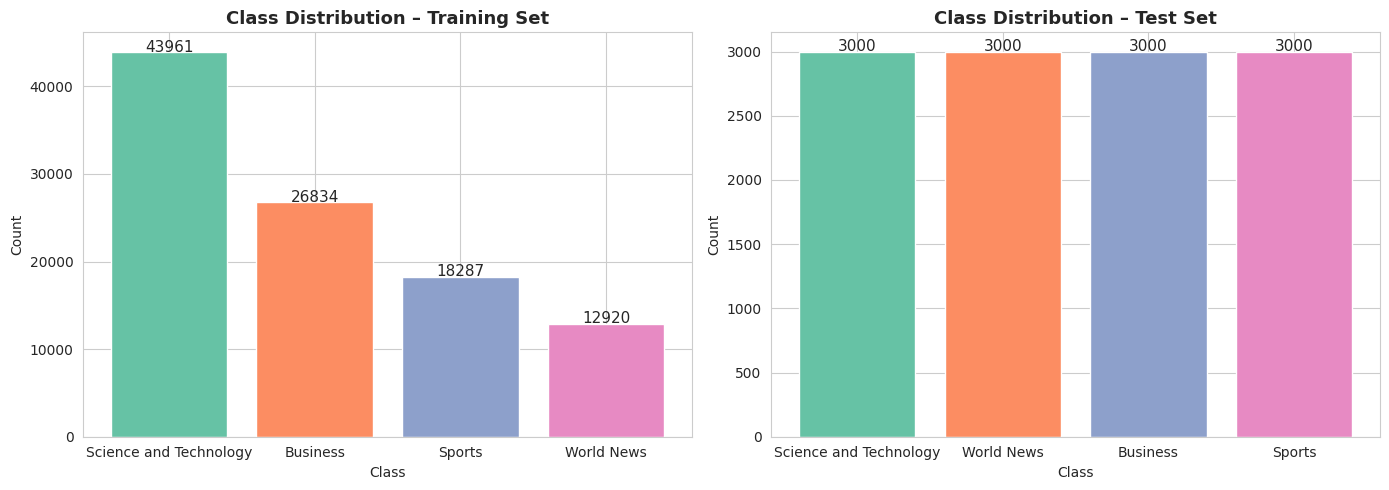


EDA Insight: Class balance check
Imbalance ratio (majority/minority): 3.40
Dataset is imbalanced.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Train
vc_train = train_df[LABEL_COL].value_counts()
axes[0].bar(vc_train.index.astype(str), vc_train.values, color=COLORS)
axes[0].set_title('Class Distribution – Training Set', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, (lbl, cnt) in enumerate(zip(vc_train.index.astype(str), vc_train.values)):
    axes[0].text(i, cnt + 10, str(cnt), ha='center', fontsize=11)

# Test
vc_test = test_df[LABEL_COL].value_counts()
axes[1].bar(vc_test.index.astype(str), vc_test.values, color=COLORS)
axes[1].set_title('Class Distribution – Test Set', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
for i, (lbl, cnt) in enumerate(zip(vc_test.index.astype(str), vc_test.values)):
    axes[1].text(i, cnt + 5, str(cnt), ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nEDA Insight: Class balance check")
majority = vc_train.max(); minority = vc_train.min()
imbalance_ratio = majority / minority
print(f"Imbalance ratio (majority/minority): {imbalance_ratio:.2f}")
if imbalance_ratio > 1.5:
    print("Dataset is imbalanced.")
else:
    print("Dataset is relatively balanced.")



--- Average word count per text entry in 'News Headline' (Training Data) ---
Average: 46.61 words
Min: 17 words
Max: 180 words


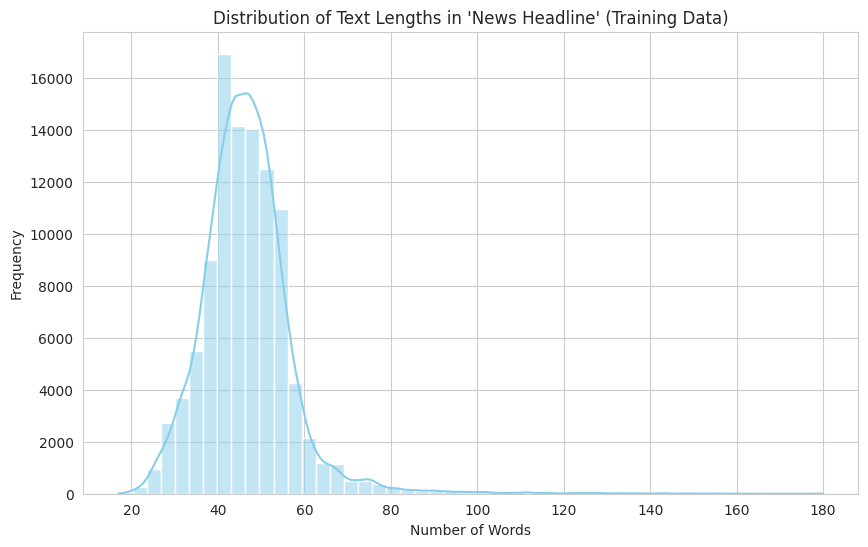

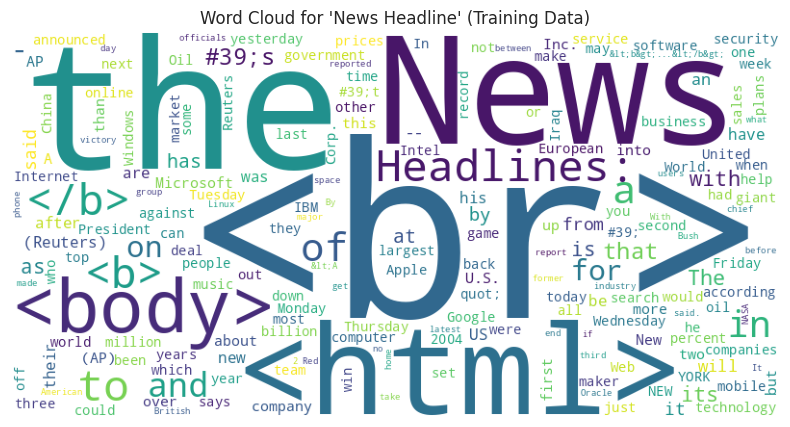

In [ ]:
text_column = 'News Headline'

if text_column in train_df.columns:
    train_df['text_length'] = train_df[text_column].apply(lambda x: len(str(x).split()))

    # Average sentence length (simple word count as proxy)
    print(f"\n--- Average word count per text entry in '{text_column}' (Training Data) ---")
    print(f"Average: {train_df['text_length'].mean():.2f} words")
    print(f"Min: {train_df['text_length'].min()} words")
    print(f"Max: {train_df['text_length'].max()} words")

    # Distribution of text lengths
    plt.figure(figsize=(10, 6))
    sns.histplot(train_df['text_length'], bins=50, kde=True, color='skyblue')
    plt.title(f'Distribution of Text Lengths in \'{text_column}\' (Training Data)')
    plt.xlabel('Number of Words')
    plt.ylabel('Frequency')
    plt.show()

    # Common words / Word Cloud
    all_text = ' '.join(train_df[text_column].dropna().astype(str))

    # Clean text for word cloud (remove non-alphabetic characters and convert to lowercase)
    clean_text = re.sub('[^a-zA-Z]', ' ', all_text).lower()

    fd = FreqDist(all_words)
    word_cloud = WordCloud(width=800, height=400, background_color='white')
    cloud = word_cloud.generate_from_frequencies(fd)

    plt.figure(figsize=(10, 5))
    plt.imshow(cloud)
    plt.axis('off')
    plt.title(f'Word Cloud for \'{text_column}\' (Training Data)')
    plt.show()

else:
    print(f"Text column '{text_column}' not found in training data. Please update the variable.")

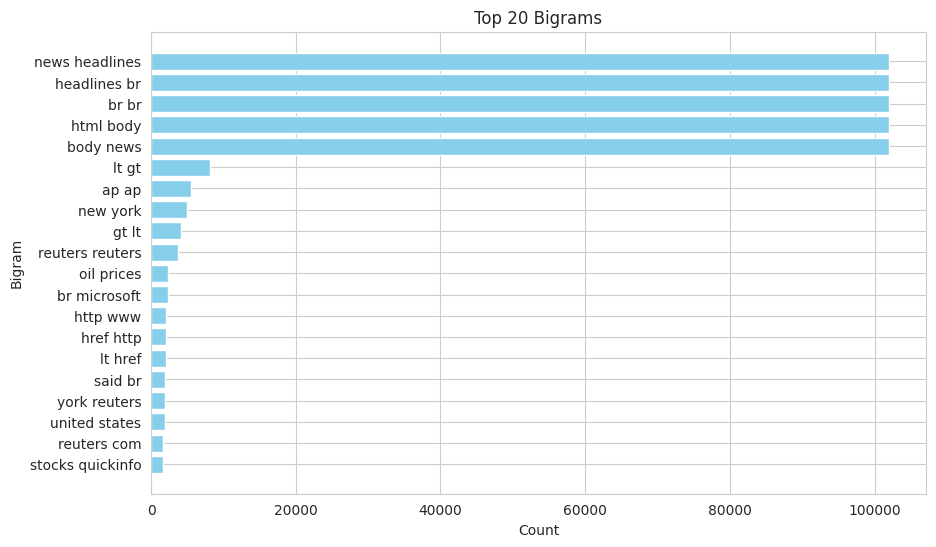

In [ ]:
# Extract bigrams
bigram_vectorizer = CountVectorizer(ngram_range=(2,2), stop_words='english', max_features=50000)
X_bigrams = bigram_vectorizer.fit_transform(train_df['News Headline'])

# Get top bigrams
bigram_counts = X_bigrams.sum(axis=0).A1
bigram_freq = pd.DataFrame({'bigram': bigram_vectorizer.get_feature_names_out(),
                            'count': bigram_counts})
top_bigrams = bigram_freq.sort_values('count', ascending=False).head(20)
# print(top_bigrams)

plt.figure(figsize=(10,6))
plt.barh(top_bigrams['bigram'], top_bigrams['count'], color='skyblue')
plt.xlabel('Count')
plt.ylabel('Bigram')
plt.title('Top 20 Bigrams')
plt.gca().invert_yaxis()  # highest at top
plt.show()

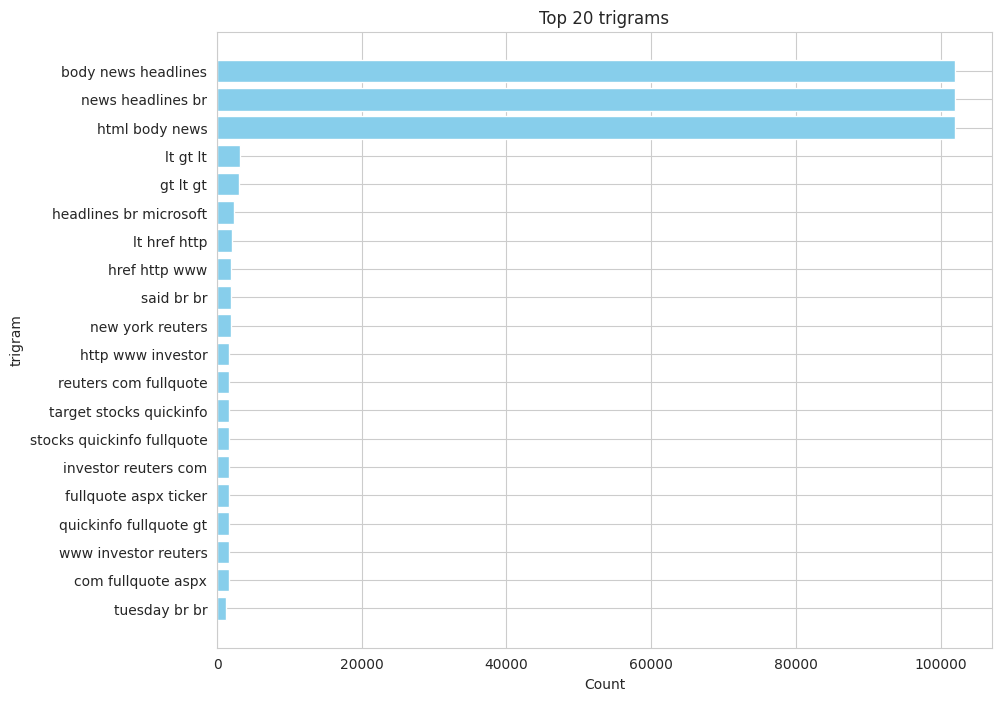

In [ ]:
# Extract trigrams
trigram_vectorizer = CountVectorizer(ngram_range=(3,3), stop_words='english', max_features=50000)
X_trigrams = trigram_vectorizer.fit_transform(train_df['News Headline'])

# Get top trigrams
trigram_counts = X_trigrams.sum(axis=0).A1
trigram_freq = pd.DataFrame({'trigram': trigram_vectorizer.get_feature_names_out(),
                             'count': trigram_counts})
top_trigrams = trigram_freq.sort_values('count', ascending=False).head(20)
# print(top_trigrams)

plt.figure(figsize=(10,8))
plt.barh(top_trigrams['trigram'], top_trigrams['count'], color='skyblue')
plt.xlabel('Count')
plt.ylabel('trigram')
plt.title('Top 20 trigrams')
plt.gca().invert_yaxis()  # highest at top
plt.show()

In [ ]:
print("Duplicate rows in training set:", train_df.duplicated().sum())
train_df = train_df.drop_duplicates().reset_index(drop=True)
print("Training shape after duplicate removal:", train_df.shape)

Duplicate rows in training set: 22287
Training shape after duplicate removal: (79715, 3)


### Data Preprecessing


In [ ]:
stop_words_set = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# ================================
# PREPROCESSING FUNCTION 1: NONE
# ================================
def preprocess_none(text):
    return str(text)


# ================================
# PREPROCESSING FUNCTION 2: EXTREME
# ================================
def preprocess_extreme(text):
    """
    Full preprocessing pipeline:
    - Lowercase
    - Remove URLs
    - Remove HTML tags
    - Remove digits
    - Remove punctuation & special characters
    - Tokenize
    - Remove stopwords
    - Remove short tokens (len < 2)
    - Stemming (PorterStemmer)
    """
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'<[^>]+>', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words_set and len(t) > 1]
    tokens = [stemmer.stem(t) for t in tokens]

    return ' '.join(tokens)


# ================================
# PREPROCESSING FUNCTION 3: OPTIMUM
# ================================
def preprocess_optimum(text):
    """
    Balanced preprocessing based on EDA insights:
    - Lowercase
    - Remove URLs and HTML
    - Keep digits (important for some contexts)
    - Remove special characters
    - Tokenize
    - Remove non-informative words
    """
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'<[^>]+>', '', text)
    text = re.sub(r"[^a-zA-Z0-9\s']", '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words_set and len(t) > 1]
    remove_tokens = {'news', 'headlines'}
    filtered_tokens = [t for t in tokens if t.lower() not in remove_tokens]

    return ' '.join(filtered_tokens)


# ================================
# SAMPLE OUTPUT CHECK
# ================================
sample = train_df["News Headline"].iloc[0]

print("Original:\n", sample[:200])
print("\nNo preprocessing:\n", preprocess_none(sample)[:200])
print("\nExtreme preprocessing:\n", preprocess_extreme(sample)[:200])
print("\nOptimum preprocessing:\n", preprocess_optimum(sample)[:200])

Original:
 <html> <body> News Headlines:
 <br> <b> Google Browser May Be Reality Google Browser May Become Reality\\There has been much fanfare in the Mozilla fan camps about the possibility of Google using Mozi

No preprocessing:
 <html> <body> News Headlines:
 <br> <b> Google Browser May Be Reality Google Browser May Become Reality\\There has been much fanfare in the Mozilla fan camps about the possibility of Google using Mozi

Extreme preprocessing:
 news headlin googl browser may realiti googl browser may becom realityther much fanfar mozilla fan camp possibl googl use mozilla browser technolog produc gbrowser googl browser past two week news spe

Optimum preprocessing:
 google browser may reality google browser may become realitythere much fanfare mozilla fan camps possibility google using mozilla browser technology produce gbrowser google browser past two weeks spec


* No preprocessing: returns the raw text data

* Extreme preprocessing: turns all texts into lowercase, removes URLs, HTML tags, digits, punctuation, special characters, splits the text into words (tokenize), removes stopwords, short tokens of length<2, uses Stemming to identify related root words, and joins them into texts

* Optimum preprocessing: turns all texts into lowercase, removes URLs, HTML tags, special characters, non-informative words, uses tokenization, keeps digits, stopwords, doesn't use stemming/lemmatizing to avoid loss of context in sequence, and joins the words back to text form

In [ ]:
TEXT_COL = "News Headline"
LABEL_COL = "News Topic"

# ================================
# 1. NO PREPROCESSING DATASET
# ================================
train_none = train_df.copy()
test_none = test_df.copy()

train_none["processed_text"] = train_none[TEXT_COL].apply(preprocess_none)
test_none["processed_text"]  = test_none[TEXT_COL].apply(preprocess_none)

train_none = train_none[["processed_text", LABEL_COL]]
test_none  = test_none[["processed_text", LABEL_COL]]

# ================================
# 2. EXTREME PREPROCESSING DATASET
# ================================
train_extreme = train_df.copy()
test_extreme = test_df.copy()

train_extreme["processed_text"] = train_extreme[TEXT_COL].apply(preprocess_extreme)
test_extreme["processed_text"]  = test_extreme[TEXT_COL].apply(preprocess_extreme)

train_extreme = train_extreme[["processed_text", LABEL_COL]]
test_extreme  = test_extreme[["processed_text", LABEL_COL]]

# ================================
# 3. OPTIMUM PREPROCESSING DATASET
# ================================
train_optimum = train_df.copy()
test_optimum = test_df.copy()

train_optimum["processed_text"] = train_optimum[TEXT_COL].apply(preprocess_optimum)
test_optimum["processed_text"]  = test_optimum[TEXT_COL].apply(preprocess_optimum)

train_optimum = train_optimum[["processed_text", LABEL_COL]]
test_optimum  = test_optimum[["processed_text", LABEL_COL]]

# ================================
# STORE DATASET
# ================================
train_none.to_csv('/content/train_none.csv', index=False)
test_none.to_csv('/content/test_none.csv', index=False)

train_extreme.to_csv('/content/train_extreme.csv', index=False)
test_extreme.to_csv('/content/test_extreme.csv', index=False)

train_optimum.to_csv('/content/train_optimum.csv', index=False)
test_optimum.to_csv('/content/test_optimum.csv', index=False)

# ================================
# CHECK OUTPUT
# ================================
print("\n------------------ NO PREPROCESSING ------------------")
display(train_none.head())

print("\n------------------ EXTREME PREPROCESSING ------------------")
display(train_extreme.head())

print("\n------------------ OPTIMUM PREPROCESSING ------------------")
display(train_optimum.head())


------------------ NO PREPROCESSING ------------------


,processed_text,News Topic
0,<html> <body> News Headlines:\n <br> <b> Googl...,Science and Technology
1,<html> <body> News Headlines:\n <br> <b> UA FO...,Sports
2,<html> <body> News Headlines:\n <br> <b> Tul I...,Science and Technology
3,<html> <body> News Headlines:\n <br> <b> Toshi...,Science and Technology
4,<html> <body> News Headlines:\n <br> <b> Micro...,Business



------------------ EXTREME PREPROCESSING ------------------


,processed_text,News Topic
0,news headlin googl browser may realiti googl b...,Science and Technology
1,news headlin ua footbal cat special incent bea...,Sports
2,news headlin tul introduc latest powercolor xp...,Science and Technology
3,news headlin toshiba win hd dvd support hollyw...,Science and Technology
4,news headlin microsoft step ring quotcompar it...,Business



------------------ OPTIMUM PREPROCESSING ------------------


,processed_text,News Topic
0,google browser may reality google browser may ...,Science and Technology
1,ua football cat special incentive beat devils ...,Sports
2,tul introduces latest powercolor xpress 200 pc...,Science and Technology
3,toshiba wins hd dvd support hollywood toshiba ...,Science and Technology
4,microsoft steps ring quotcompared itunes micro...,Business


### Get Split Dataset

In [ ]:
train_none = pd.read_csv('/content/train_none.csv')
train_extreme = pd.read_csv('/content/train_extreme.csv')
train_optimum = pd.read_csv('/content/train_optimum.csv')

test_none = pd.read_csv('/content/test_none.csv')
test_extreme = pd.read_csv('/content/test_extreme.csv')
test_optimum = pd.read_csv('/content/test_optimum.csv')

### Label Encoding and Train-Validation Split


In [ ]:
le = LabelEncoder()

train_none['label'] = le.fit_transform(train_none['News Topic'])
test_none['label'] = le.transform(test_none['News Topic'])

train_extreme['label'] = le.transform(train_extreme['News Topic'])
test_extreme['label'] = le.transform(test_extreme['News Topic'])

train_optimum['label'] = le.transform(train_optimum['News Topic'])
test_optimum['label'] = le.transform(test_optimum['News Topic'])

print("Encoded classes:", list(le.classes_))

Encoded classes: ['Business', 'Science and Technology', 'Sports', 'World News']


Label Encoding used to transform categorical target classes, ['Business', 'Science and Technology', 'Sports', 'World News'] into numerical targets [0, 1, 2, 3], for models to predict

In [ ]:
def make_train_val_split(df):
    X = df["processed_text"]
    y = df["label"]

    X_train, X_val, y_train, y_val = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
    return X_train, X_val, y_train, y_val

From the given training dataset, 80% used as training data and 20% used as validation data

### Experiment 1A: TF-IDF + Logistic Regression (No Preprocessing)


In [ ]:
prep_results = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_none)

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

val_pred = lr_model.predict(X_val_tfidf)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

Validation Accuracy: 0.9071692905977545
Validation Macro F1: 0.907495835605092

Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.90      0.90      5367
Science and Technology       0.87      0.89      0.88      4335
                Sports       0.95      0.97      0.96      3657
            World News       0.92      0.86      0.89      2584

              accuracy                           0.91     15943
             macro avg       0.91      0.91      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



In [ ]:
param_grid = [
    {"max_features": 5000, "ngram_range": (1,1), "C": 1},
    {"max_features": 10000, "ngram_range": (1,2), "C": 1},
    {"max_features": 20000, "ngram_range": (1,2), "C": 1},
    {"max_features": 10000, "ngram_range": (1,2), "C": 0.5},
]

results = []

X_train, X_val, y_train, y_val = make_train_val_split(train_none)

for params in param_grid:

    tfidf = TfidfVectorizer(
        max_features=params["max_features"],
        ngram_range=params["ngram_range"],
        min_df=2
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_val_tfidf = tfidf.transform(X_val)

    model = LogisticRegression(
        max_iter=1000,
        C=params["C"]
    )

    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_val_tfidf)

    acc = accuracy_score(y_val, pred)
    f1 = f1_score(y_val, pred, average='macro')

    results.append({
        "Preprocessing": "None",
        "Representation": "TF-IDF",
        "Model": "Logistic Regression",
        "max_features": params["max_features"],
        "ngram_range": str(params["ngram_range"]),
        "C": params["C"],
        "Validation Accuracy": acc,
        "Validation Macro F1": f1
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Validation Macro F1", ascending=False))

,Preprocessing,Representation,Model,max_features,ngram_range,C,Validation Accuracy,Validation Macro F1
2,None,TF-IDF,Logistic Regression,20000,"(1, 2)",1.0,0.911058,0.911547
1,None,TF-IDF,Logistic Regression,10000,"(1, 2)",1.0,0.907169,0.907496
3,None,TF-IDF,Logistic Regression,10000,"(1, 2)",0.5,0.905852,0.906298
0,None,TF-IDF,Logistic Regression,5000,"(1, 1)",1.0,0.905288,0.905680


In [ ]:
best_tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf = best_tfidf.fit_transform(X_train)
X_val_tfidf = best_tfidf.transform(X_val)

best_lr = LogisticRegression(max_iter=1000, C=1)
best_lr.fit(X_train_tfidf, y_train)

val_pred = best_lr.predict(X_val_tfidf)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

results.append({
    "Preprocessing": "None",
    "Representation": "TF-IDF",
    "Model": "Logistic Regression",
    "max_features": 20000,
    "ngram_range": "(1,2)",
    "C": 1,
    "Validation Accuracy": round(acc,4),
    "Validation Macro F1": round(f1,4)
})

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'None',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Validation Accuracy: 0.911058144640281
Validation Macro F1: 0.9115474817151487

Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.90      0.90      5367
Science and Technology       0.87      0.90      0.89      4335
                Sports       0.96      0.98      0.97      3657
            World News       0.92      0.86      0.89      2584

              accuracy                           0.91     15943
             macro avg       0.91      0.91      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



### Experiment 1B: TF-IDF + Logistic Regression (Extreme Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_extreme)

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

val_pred = lr_model.predict(X_val_tfidf)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Extreme',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Validation Accuracy: 0.9118735495201656
Validation Macro F1: 0.9125900686553657

Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.90      0.90      5367
Science and Technology       0.87      0.89      0.88      4335
                Sports       0.96      0.98      0.97      3657
            World News       0.92      0.86      0.89      2584

              accuracy                           0.91     15943
             macro avg       0.92      0.91      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



### Experiment 1C: TF-IDF + Logistic Regression (Optimum Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

val_pred = lr_model.predict(X_val_tfidf)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Optimum',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Validation Accuracy: 0.913065295113843
Validation Macro F1: 0.9134253220752094

Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.91      0.90      5367
Science and Technology       0.88      0.90      0.89      4335
                Sports       0.96      0.98      0.97      3657
            World News       0.92      0.86      0.89      2584

              accuracy                           0.91     15943
             macro avg       0.92      0.91      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



### Comparison of 3 Preprocessing techniques based on TF-IDF + Logistic Regression

In [ ]:
df = pd.DataFrame(prep_results)
df

,Preprocessing,Accuracy,Precision,Recall,F1-score
0,None,0.9111,0.9113,0.9111,0.9109
1,Extreme,0.9119,0.9120,0.9119,0.9117
2,Optimum,0.9131,0.9132,0.9131,0.9129


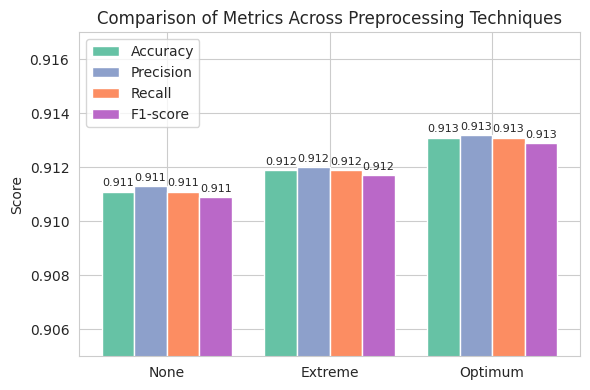

In [ ]:
models = df['Preprocessing'].tolist()

accuracies = df['Accuracy'].tolist()
precisions = df['Precision'].tolist()
recalls = df['Recall'].tolist()
f1_scores = df['F1-score'].tolist()

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(6,4))

plt.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#66C2A5')
plt.bar(x - 0.5*width, precisions, width, label='Precision', color='#8DA0CB')
plt.bar(x + 0.5*width, recalls, width, label='Recall', color='#FC8D62')
plt.bar(x + 1.5*width, f1_scores, width, label='F1-score', color='#BA68C8')

plt.xticks(x, models)
plt.ylim(0.905, 0.917)
plt.ylabel('Score')
plt.title('Comparison of Metrics Across Preprocessing Techniques')
plt.legend()

for i in range(len(models)):
    plt.text(i - 1.5*width, accuracies[i] + 0.0002, f"{accuracies[i]:.3f}", ha='center', fontsize=8)
    plt.text(i - 0.5*width, precisions[i] + 0.0002, f"{precisions[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 0.5*width, recalls[i] + 0.0002, f"{recalls[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 1.5*width, f1_scores[i] + 0.0002, f"{f1_scores[i]:.3f}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

### Experiment 2A: TF-IDF + Deep Neural Network (No Preprocessing)


In [ ]:
prep_results = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_none)

print(f'Feature size: Train data, Validation data = {len(X_train)}, {len(X_val)}')
print(f'Target size: Train data, Validation data = {len(y_train)}, {len(y_val)}')

tfidf_dnn = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf_dnn = tfidf_dnn.fit_transform(X_train).astype('float32')
X_val_tfidf_dnn = tfidf_dnn.transform(X_val).astype('float32')

print("Sparse train shape:", X_train_tfidf_dnn.shape)
print("Sparse val shape:", X_val_tfidf_dnn.shape)

X_train_dense = X_train_tfidf_dnn.toarray()
X_val_dense = X_val_tfidf_dnn.toarray()

print("Dense train shape:", X_train_dense.shape)
print("Dense val shape:", X_val_dense.shape)

Feature size: Train data, Validation data = 63772, 15943
Target size: Train data, Validation data = 63772, 15943
Sparse train shape: (63772, 10000)
Sparse val shape: (15943, 10000)
Dense train shape: (63772, 10000)
Dense val shape: (15943, 10000)


In [ ]:
dnn_model = Sequential([
    Input(shape=(X_train_dense.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

dnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = dnn_model.fit(
    X_train_dense, y_train,
    validation_data=(X_val_dense, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.8751 - loss: 0.3574 - val_accuracy: 0.9045 - val_loss: 0.2703
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9368 - loss: 0.1846 - val_accuracy: 0.8976 - val_loss: 0.3214
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9655 - loss: 0.1003 - val_accuracy: 0.8959 - val_loss: 0.4506
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9817 - loss: 0.0511 - val_accuracy: 0.8970 - val_loss: 0.5841


In [ ]:
val_prob = dnn_model.predict(X_val_dense)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'None',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Accuracy: 0.9045349056012043
Validation Macro F1: 0.9051188123410877

Classification Report:
                        precision    recall  f1-score   support

              Business       0.92      0.87      0.90      5367
Science and Technology       0.84      0.91      0.88      4335
                Sports       0.96      0.97      0.97      3657
            World News       0.91      0.86      0.88      2584

              accuracy                           0.90     15943
             macro avg       0.91      0.90      0.91     15943
          weighted avg       0.91      0.90      0.90     15943



### Experiment 2B: TF-IDF + Deep Neural Network (Extreme Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_extreme)

print(f'Feature size: Train data, Validation data = {len(X_train)}, {len(X_val)}')
print(f'Target size: Train data, Validation data = {len(y_train)}, {len(y_val)}')

tfidf_dnn = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf_dnn = tfidf_dnn.fit_transform(X_train).astype('float32')
X_val_tfidf_dnn = tfidf_dnn.transform(X_val).astype('float32')

print("Sparse train shape:", X_train_tfidf_dnn.shape)
print("Sparse val shape:", X_val_tfidf_dnn.shape)

X_train_dense = X_train_tfidf_dnn.toarray()
X_val_dense = X_val_tfidf_dnn.toarray()

print("Dense train shape:", X_train_dense.shape)
print("Dense val shape:", X_val_dense.shape)

Feature size: Train data, Validation data = 63772, 15943
Target size: Train data, Validation data = 63772, 15943
Sparse train shape: (63772, 10000)
Sparse val shape: (15943, 10000)
Dense train shape: (63772, 10000)
Dense val shape: (15943, 10000)


In [ ]:
dnn_model = Sequential([
    Input(shape=(X_train_dense.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

dnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = dnn_model.fit(
    X_train_dense, y_train,
    validation_data=(X_val_dense, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8797 - loss: 0.3483 - val_accuracy: 0.9057 - val_loss: 0.2682
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9354 - loss: 0.1885 - val_accuracy: 0.9066 - val_loss: 0.3014
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9610 - loss: 0.1121 - val_accuracy: 0.9016 - val_loss: 0.3967
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9785 - loss: 0.0598 - val_accuracy: 0.8953 - val_loss: 0.5444


In [ ]:
val_prob = dnn_model.predict(X_val_dense)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Extreme',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Accuracy: 0.9057266511948817
Validation Macro F1: 0.9067244135096426

Classification Report:
                        precision    recall  f1-score   support

              Business       0.93      0.86      0.90      5367
Science and Technology       0.83      0.93      0.88      4335
                Sports       0.96      0.98      0.97      3657
            World News       0.93      0.84      0.88      2584

              accuracy                           0.91     15943
             macro avg       0.91      0.90      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



### Experiment 2C: TF-IDF + Deep Neural Network (Optimum Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

print(f'Feature size: Train data, Validation data = {len(X_train)}, {len(X_val)}')
print(f'Target size: Train data, Validation data = {len(y_train)}, {len(y_val)}')

tfidf_dnn = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf_dnn = tfidf_dnn.fit_transform(X_train).astype('float32')
X_val_tfidf_dnn = tfidf_dnn.transform(X_val).astype('float32')

print("Sparse train shape:", X_train_tfidf_dnn.shape)
print("Sparse val shape:", X_val_tfidf_dnn.shape)

X_train_dense = X_train_tfidf_dnn.toarray()
X_val_dense = X_val_tfidf_dnn.toarray()

print("Dense train shape:", X_train_dense.shape)
print("Dense val shape:", X_val_dense.shape)

Feature size: Train data, Validation data = 63772, 15943
Target size: Train data, Validation data = 63772, 15943
Sparse train shape: (63772, 10000)
Sparse val shape: (15943, 10000)
Dense train shape: (63772, 10000)
Dense val shape: (15943, 10000)


In [ ]:
dnn_model = Sequential([
    Input(shape=(X_train_dense.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

dnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = dnn_model.fit(
    X_train_dense, y_train,
    validation_data=(X_val_dense, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.8777 - loss: 0.3560 - val_accuracy: 0.9064 - val_loss: 0.2733
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9367 - loss: 0.1839 - val_accuracy: 0.9055 - val_loss: 0.3093
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9640 - loss: 0.1031 - val_accuracy: 0.9017 - val_loss: 0.3989
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9814 - loss: 0.0530 - val_accuracy: 0.8982 - val_loss: 0.5510


In [ ]:
val_prob = dnn_model.predict(X_val_dense)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print("\nClassification Report:")
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Optimum',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Accuracy: 0.9063538857178699
Validation Macro F1: 0.9071011613855295

Classification Report:
                        precision    recall  f1-score   support

              Business       0.93      0.87      0.90      5367
Science and Technology       0.83      0.93      0.88      4335
                Sports       0.96      0.98      0.97      3657
            World News       0.92      0.85      0.88      2584

              accuracy                           0.91     15943
             macro avg       0.91      0.91      0.91     15943
          weighted avg       0.91      0.91      0.91     15943



### Comparison of 3 Preprocessing techniques based on TF-IDF + Deep Neural Network

In [ ]:
df = pd.DataFrame(prep_results)
df

,Preprocessing,Accuracy,Precision,Recall,F1-score
0,None,0.9045,0.9061,0.9045,0.9046
1,Extreme,0.9057,0.9093,0.9057,0.9057
2,Optimum,0.9064,0.9090,0.9064,0.9064


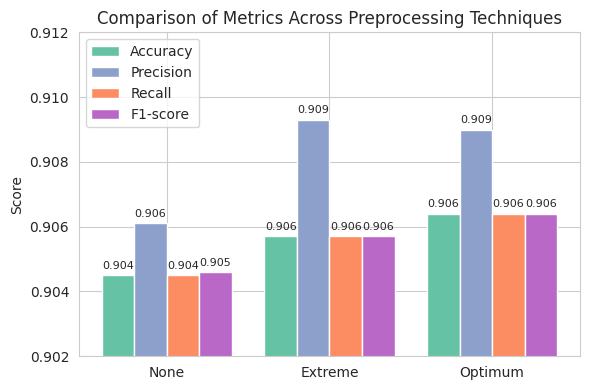

In [ ]:
models = df['Preprocessing'].tolist()

accuracies = df['Accuracy'].tolist()
precisions = df['Precision'].tolist()
recalls = df['Recall'].tolist()
f1_scores = df['F1-score'].tolist()

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(6,4))

plt.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#66C2A5')
plt.bar(x - 0.5*width, precisions, width, label='Precision', color='#8DA0CB')
plt.bar(x + 0.5*width, recalls, width, label='Recall', color='#FC8D62')
plt.bar(x + 1.5*width, f1_scores, width, label='F1-score', color='#BA68C8')

plt.xticks(x, models)
plt.ylim(0.902, 0.912)
plt.ylabel('Score')
plt.title('Comparison of Metrics Across Preprocessing Techniques')
plt.legend()

for i in range(len(models)):
    plt.text(i - 1.5*width, accuracies[i] + 0.0002, f"{accuracies[i]:.3f}", ha='center', fontsize=8)
    plt.text(i - 0.5*width, precisions[i] + 0.0002, f"{precisions[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 0.5*width, recalls[i] + 0.0002, f"{recalls[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 1.5*width, f1_scores[i] + 0.0002, f"{f1_scores[i]:.3f}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

### Experiment 3A: Skipgram + Simple Recurrent Neural Network (No Preprocessing)


In [ ]:
prep_results = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_none)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

embedding_dim = 100

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

tokenized_val = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_val_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print("Train padded shape:", X_train_pad.shape)
print("Val padded shape:", X_val_pad.shape)

Train padded shape: (63772, 100)
Val padded shape: (15943, 100)


In [ ]:
simple_rnn_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=False
    ),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(len(le.classes_), activation='softmax')
])

simple_rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

NameError: name 'Sequential' is not defined

In [ ]:
`early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = simple_rnn_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = simple_rnn_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'None',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

SyntaxError: invalid syntax (1030390723.py, line 1)

### Experiment 3B: Skipgram + Simple Recurrent Neural Network (Extreme Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_extreme)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

embedding_dim = 100

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

tokenized_val = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_val_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print("Train padded shape:", X_train_pad.shape)
print("Val padded shape:", X_val_pad.shape)

NameError: name 'make_train_val_split' is not defined

In [ ]:
simple_rnn_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=False
    ),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(len(le.classes_), activation='softmax')
])

simple_rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = simple_rnn_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = simple_rnn_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Extreme',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

NameError: name 'EarlyStopping' is not defined

### Experiment 3C: Skipgram + Simple Recurrent Neural Network (Optimum Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

embedding_dim = 100

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

tokenized_val = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_val_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print("Train padded shape:", X_train_pad.shape)
print("Val padded shape:", X_val_pad.shape)

NameError: name 'make_train_val_split' is not defined

In [ ]:
simple_rnn_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=False
    ),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(len(le.classes_), activation='softmax')
])

simple_rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = simple_rnn_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = simple_rnn_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Optimum',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

NameError: name 'EarlyStopping' is not defined

### Comparison of 3 Preprocessing techniques based on Skipgram + Simple Recurrent Neural Network

In [ ]:
df = pd.DataFrame(prep_results)
df

NameError: name 'pd' is not defined

In [ ]:
models = df['Preprocessing'].tolist()

accuracies = df['Accuracy'].tolist()
precisions = df['Precision'].tolist()
recalls = df['Recall'].tolist()
f1_scores = df['F1-score'].tolist()

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(6,4))

plt.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#66C2A5')
plt.bar(x - 0.5*width, precisions, width, label='Precision', color='#8DA0CB')
plt.bar(x + 0.5*width, recalls, width, label='Recall', color='#FC8D62')
plt.bar(x + 1.5*width, f1_scores, width, label='F1-score', color='#BA68C8')

plt.xticks(x, models)
plt.ylim(0.07, 0.4)
plt.ylabel('Score')
plt.title('Comparison of Metrics Across Preprocessing Techniques')
plt.legend()

for i in range(len(models)):
    plt.text(i - 1.5*width, accuracies[i] + 0.0002, f"{accuracies[i]:.3f}", ha='center', fontsize=8)
    plt.text(i - 0.5*width, precisions[i] + 0.0002, f"{precisions[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 0.5*width, recalls[i] + 0.0002, f"{recalls[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 1.5*width, f1_scores[i] + 0.0002, f"{f1_scores[i]:.3f}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

SimpleRNN showed consistent poor performance across all preprocessing techniques, with accuracy remaining near baseline (33%). This indicates that preprocessing did not have much impact on its performance. The model failed to learn meaningful patterns.

### Experiment 4A: Skipgram + Bidirectional LSTM (No Preprocessing)


In [ ]:
prep_results = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_none)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)
embedding_dim = 100

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

In [ ]:
bilstm_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=True
    ),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

bilstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = bilstm_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'None',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 36s 15ms/step - accuracy: 0.8725 - loss: 0.3735 - val_accuracy: 0.9156 - val_loss: 0.2617
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.9292 - loss: 0.2240 - val_accuracy: 0.9158 - val_loss: 0.2542
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 30s 15ms/step - accuracy: 0.9466 - loss: 0.1702 - val_accuracy: 0.9133 - val_loss: 0.2837
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.9579 - loss: 0.1284 - val_accuracy: 0.9074 - val_loss: 0.3405
Epoch 5/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9683 - loss: 0.0970 - val_accuracy: 0.9068 - val_loss: 0.4084
499/499 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
Validation Accuracy: 0.9158251270149909
Validation Macro F1: 0.9160944648832524
                        precision    recall  f1-score   support

              Business       0.91      0.91      0.91      5367
Science and Technology       0.86      0.91      0.89      4335
                Sports    

### Experiment 4B: Skipgram + Bidirectional LSTM (Extreme Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_extreme)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)
embedding_dim = 100

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

In [ ]:
bilstm_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=True
    ),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

bilstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = bilstm_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Extreme',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 32s 15ms/step - accuracy: 0.8851 - loss: 0.3449 - val_accuracy: 0.9118 - val_loss: 0.2550
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.9271 - loss: 0.2273 - val_accuracy: 0.9163 - val_loss: 0.2481
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9427 - loss: 0.1756 - val_accuracy: 0.9045 - val_loss: 0.2994
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.9556 - loss: 0.1356 - val_accuracy: 0.9069 - val_loss: 0.3417
Epoch 5/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.9640 - loss: 0.1059 - val_accuracy: 0.9022 - val_loss: 0.3928
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Validation Accuracy: 0.9163269146333815
Validation Macro F1: 0.9168430694974578
                        precision    recall  f1-score   support

              Business       0.92      0.90      0.91      5367
Science and Technology       0.87      0.91      0.89      4335
                Sports    

### Experiment 4C: Skipgram + Bidirectional LSTM (Optimum Preprocessing)


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

max_len = 100

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')

word_index = tokenizer.word_index
index_word = tokenizer.index_word

num_tokens = min(20000, len(word_index) + 1)
embedding_dim = 100

tokenized_train = [
    [index_word.get(idx, "<OOV>") for idx in seq if idx != 0]
    for seq in X_train_seq
]

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((num_tokens, embedding_dim))

for word, idx in word_index.items():
    if idx >= num_tokens:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

In [ ]:
bilstm_model = Sequential([
    Embedding(
        input_dim=num_tokens,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_len,
        trainable=True
    ),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

bilstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_prob = bilstm_model.predict(X_val_pad)
val_pred = np.argmax(val_prob, axis=1)

acc = accuracy_score(y_val, val_pred)
f1 = f1_score(y_val, val_pred, average='macro')

print("Validation Accuracy:", acc)
print("Validation Macro F1:", f1)
print(classification_report(y_val, val_pred, target_names=le.classes_))

report = classification_report(y_val, val_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results.append({
    'Preprocessing': 'Optimum',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 33s 15ms/step - accuracy: 0.8887 - loss: 0.3343 - val_accuracy: 0.9148 - val_loss: 0.2446
Epoch 2/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9314 - loss: 0.2137 - val_accuracy: 0.9170 - val_loss: 0.2417
Epoch 3/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9486 - loss: 0.1555 - val_accuracy: 0.9102 - val_loss: 0.2986
Epoch 4/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 30s 15ms/step - accuracy: 0.9616 - loss: 0.1126 - val_accuracy: 0.9064 - val_loss: 0.3469
Epoch 5/20
1993/1993 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.9718 - loss: 0.0811 - val_accuracy: 0.9100 - val_loss: 0.3977
499/499 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
Validation Accuracy: 0.9170168726086684
Validation Macro F1: 0.917860809467965
                        precision    recall  f1-score   support

              Business       0.92      0.90      0.91      5367
Science and Technology       0.87      0.91      0.89      4335
                Sports     

### Comparison of 3 Preprocessing techniques based on Skipgram + Bidirectional LSTM

In [ ]:
df = pd.DataFrame(prep_results)
df

,Preprocessing,Accuracy,Precision,Recall,F1-score
0,None,0.9158,0.9171,0.9158,0.9159
1,Extreme,0.9163,0.9168,0.9163,0.9161
2,Optimum,0.9170,0.9174,0.9170,0.9169


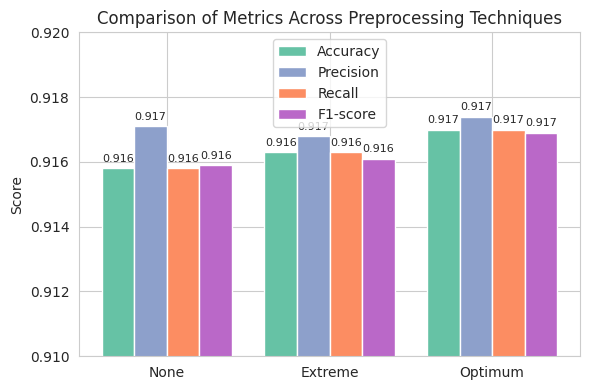

In [ ]:
models = df['Preprocessing'].tolist()

accuracies = df['Accuracy'].tolist()
precisions = df['Precision'].tolist()
recalls = df['Recall'].tolist()
f1_scores = df['F1-score'].tolist()

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(6,4))

plt.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#66C2A5')
plt.bar(x - 0.5*width, precisions, width, label='Precision', color='#8DA0CB')
plt.bar(x + 0.5*width, recalls, width, label='Recall', color='#FC8D62')
plt.bar(x + 1.5*width, f1_scores, width, label='F1-score', color='#BA68C8')

plt.xticks(x, models)
plt.ylim(0.91, 0.92)
plt.ylabel('Score')
plt.title('Comparison of Metrics Across Preprocessing Techniques')
plt.legend()

for i in range(len(models)):
    plt.text(i - 1.5*width, accuracies[i] + 0.0002, f"{accuracies[i]:.3f}", ha='center', fontsize=8)
    plt.text(i - 0.5*width, precisions[i] + 0.0002, f"{precisions[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 0.5*width, recalls[i] + 0.0002, f"{recalls[i]:.3f}", ha='center', fontsize=8)
    plt.text(i + 1.5*width, f1_scores[i] + 0.0002, f"{f1_scores[i]:.3f}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

Preprocessing has a positive but small impact, with 'Optimum preprocessing' giving the best and most balanced results, and 'No preprocessing'.giving the worst results (while all the metrics having score within 0.90-0.92).

Except for SimpleRNN, this model failed to capture meaningful information, missclassifying most of the test data thoughout all 3 preprocessing.

However, even without preprocessing, the model performs strongly, indicating that the dataset is clean and the models are strong, without totally depending on preprocessing techniques.

* Based on the results, training All Models on Best Preprocessing technique, which is Optimum Preprocessing

### Model: TF-IDF + LOGISTIC REGRESSION


In [ ]:
prep_results_test = []

In [ ]:
prep_results_val = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

In [ ]:
tfidf_A = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf_A = tfidf_A.fit_transform(X_train)
X_val_tfidf_A = tfidf_A.transform(X_val)

lr_A = LogisticRegression(
    max_iter=1000,
    C=2,
    solver='saga'
)

lr_A.fit(X_train_tfidf_A, y_train)

train_pred_A = lr_A.predict(X_train_tfidf_A)
val_pred_A = lr_A.predict(X_val_tfidf_A)

train_acc_A = accuracy_score(y_train, train_pred_A)
val_acc_A = accuracy_score(y_val, val_pred_A)
val_f1_A = f1_score(y_val, val_pred_A, average='macro')

print("LR_A Train Accuracy:", train_acc_A)
print("LR_A Validation Accuracy:", val_acc_A)
print("LR_A Validation Macro F1:", val_f1_A)

print("\nLR_A Classification Report:")
print(classification_report(y_val, val_pred_A, target_names=le.classes_))

report = classification_report(y_val, val_pred_A, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'A',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

LR_A Train Accuracy: 0.9612259653680715
LR_A Validation Accuracy: 0.9328464290966129
LR_A Validation Macro F1: 0.9290119435562049

LR_A Classification Report:
                        precision    recall  f1-score   support

              Business       0.92      0.88      0.90      5367
Science and Technology       0.92      0.97      0.94      8792
                Sports       0.97      0.98      0.97      3658
            World News       0.94      0.86      0.90      2584

              accuracy                           0.93     20401
             macro avg       0.94      0.92      0.93     20401
          weighted avg       0.93      0.93      0.93     20401



In [ ]:
tfidf_B = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf_B = tfidf_B.fit_transform(X_train)
X_val_tfidf_B = tfidf_B.transform(X_val)

lr_B = LogisticRegression(
    max_iter=2000,
    C=2,
    solver='lbfgs',
    class_weight='balanced'
)

lr_B.fit(X_train_tfidf_B, y_train)

train_pred_B = lr_B.predict(X_train_tfidf_B)
val_pred_B = lr_B.predict(X_val_tfidf_B)

train_acc_B = accuracy_score(y_train, train_pred_B)
val_acc_B = accuracy_score(y_val, val_pred_B)
val_f1_B = f1_score(y_val, val_pred_B, average='macro')

print("LR_B Train Accuracy:", train_acc_B)
print("LR_B Validation Accuracy:", val_acc_B)
print("LR_B Validation Macro F1:", val_f1_B)

print("\nLR_B Classification Report:")
print(classification_report(y_val, val_pred_B, target_names=le.classes_))

report = classification_report(y_val, val_pred_B, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'B',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

LR_B Train Accuracy: 0.9577211063589907
LR_B Validation Accuracy: 0.9275525709524043
LR_B Validation Macro F1: 0.9247931360944311

LR_B Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.89      0.90      5367
Science and Technology       0.94      0.93      0.94      8792
                Sports       0.96      0.98      0.97      3658
            World News       0.88      0.90      0.89      2584

              accuracy                           0.93     20401
             macro avg       0.92      0.93      0.92     20401
          weighted avg       0.93      0.93      0.93     20401



* max iteration 1000/2000 -> no change in result
* solver lbfgs/saga -> no change in result
* class_weight=balanced -> accuracy almost same (drops slightly)


In [ ]:
df = pd.DataFrame(prep_results_val)
df

,Model,Accuracy,Precision,Recall,F1-score
0,A,0.9329,0.9330,0.9329,0.9324
1,B,0.9276,0.9275,0.9276,0.9275


In [ ]:
X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

X_test_tfidf_A = tfidf_A.transform(X_test)

test_pred_lr = lr_A.predict(X_test_tfidf_A)

print("Classification Report: TF-IDF + LOGISTIC REGRESSION")
print(classification_report(y_test, test_pred_lr, target_names=le.classes_))

lr_report = classification_report(y_test, test_pred_lr, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'TF-IDF + LOGISTIC REGRESSION',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Classification Report: TF-IDF + LOGISTIC REGRESSION
                        precision    recall  f1-score   support

              Business       0.89      0.90      0.89      3000
Science and Technology       0.86      0.93      0.89      3000
                Sports       0.96      0.98      0.97      3000
            World News       0.96      0.86      0.91      3000

              accuracy                           0.92     12000
             macro avg       0.92      0.92      0.92     12000
          weighted avg       0.92      0.92      0.92     12000



In [ ]:
lr_pred = pd.DataFrame(test_pred_lr)
lr_pred.to_csv("lr_pred_results.csv", index=False)

### Model: TF-IDF + Deep Neural Network


In [ ]:
prep_results_val = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

In [ ]:
import gc
tfidf_A = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf_A = tfidf_A.fit_transform(X_train).astype('float32').toarray()
X_val_tfidf_A = tfidf_A.transform(X_val).astype('float32').toarray()

tf.keras.backend.clear_session()
gc.collect()

model_A = Sequential([
    Input(shape=(X_train_tfidf_A.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.30),
    Dense(192, activation='relu'),
    Dropout(0.25),
    Dense(128, activation='relu'),
    Dropout(0.20),
    Dense(64, activation='relu'),
    Dropout(0.15),
    Dense(len(le.classes_), activation='softmax')
])

model_A.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_A = model_A.fit(
    X_train_tfidf_A, y_train,
    validation_data=(X_val_tfidf_A, y_val),
    epochs=12,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_loss_A, val_acc_A = model_A.evaluate(X_val_tfidf_A, y_val, verbose=0)

val_prob_A = model_A.predict(X_val_tfidf_A)
val_pred_A = np.argmax(val_prob_A, axis=1)
val_f1_A = f1_score(y_val, val_pred_A, average='macro')

print("DNN_A Validation Loss:", val_loss_A)
print("DNN_A Validation Accuracy:", val_acc_A)
print("DNN_A Validation Macro F1:", val_f1_A)

print("\nDNN_A Classification Report:")
print(classification_report(y_val, val_pred_A, target_names=le.classes_))

report = classification_report(y_val, val_pred_A, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'A',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - accuracy: 0.8817 - loss: 0.3515 - val_accuracy: 0.9211 - val_loss: 0.2513
Epoch 2/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9386 - loss: 0.1961 - val_accuracy: 0.9273 - val_loss: 0.2455
Epoch 3/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9639 - loss: 0.1176 - val_accuracy: 0.9292 - val_loss: 0.2883
Epoch 4/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9770 - loss: 0.0718 - val_accuracy: 0.9300 - val_loss: 0.3801
Epoch 5/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9847 - loss: 0.0468 - val_accuracy: 0.9307 - val_loss: 0.4086
638/638 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
DNN_A Validation Loss: 0.2454785257577896
DNN_A Validation Accuracy: 0.9273074865341187
DNN_A Validation Macro F1: 0.9228535157821347

DNN_A Classification Report:
                        precision    recall  f1-score   support

              Business       0.90      0.88      0.89      5367
Science and 

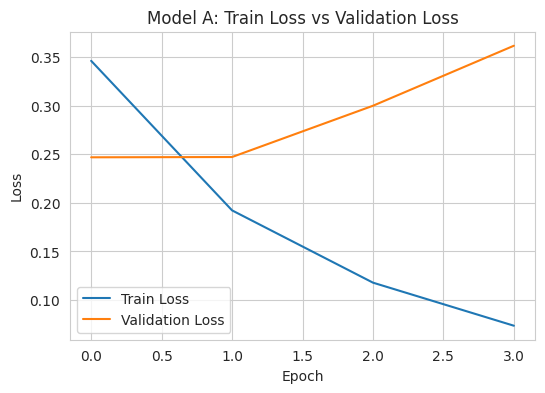

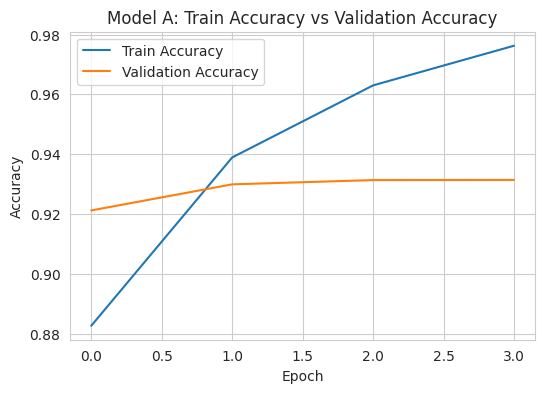

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_A.history['loss'], label='Train Loss')
plt.plot(history_A.history['val_loss'], label='Validation Loss')
plt.title("Model A: Train Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_A.history['accuracy'], label='Train Accuracy')
plt.plot(history_A.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model A: Train Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import gc
tfidf_B = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1,1),
    min_df=3,
    sublinear_tf=True
)

X_train_tfidf_B = tfidf_B.fit_transform(X_train).astype('float32').toarray()
X_val_tfidf_B = tfidf_B.transform(X_val).astype('float32').toarray()

tf.keras.backend.clear_session()
gc.collect()

model_B = Sequential([
    Input(shape=(X_train_tfidf_B.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.30),
    Dense(192, activation='relu'),
    Dropout(0.20),
    Dense(128, activation='relu'),
    Dropout(0.20),
    Dense(64, activation='relu'),
    Dropout(0.15),
    Dense(32, activation='relu'),
    Dropout(0.15),
    Dense(16, activation='relu'),
    Dropout(0.10),
    Dense(len(le.classes_), activation='softmax')
])

model_B.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_B = model_B.fit(
    X_train_tfidf_B, y_train,
    validation_data=(X_val_tfidf_B, y_val),
    epochs=12,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_loss_B, val_acc_B = model_B.evaluate(X_val_tfidf_B, y_val, verbose=0)

val_prob_B = model_B.predict(X_val_tfidf_B)
val_pred_B = np.argmax(val_prob_B, axis=1)
val_f1_B = f1_score(y_val, val_pred_B, average='macro')

print("DNN_B Validation Loss:", val_loss_B)
print("DNN_B Validation Accuracy:", val_acc_B)
print("DNN_B Validation Macro F1:", val_f1_B)

print("\nDNN_B Classification Report:")
print(classification_report(y_val, val_pred_B, target_names=le.classes_))

report = classification_report(y_val, val_pred_B, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'B',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.8620 - loss: 0.4163 - val_accuracy: 0.9109 - val_loss: 0.2788
Epoch 2/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9225 - loss: 0.2545 - val_accuracy: 0.9183 - val_loss: 0.2687
Epoch 3/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9470 - loss: 0.1824 - val_accuracy: 0.9247 - val_loss: 0.2775
Epoch 4/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9631 - loss: 0.1272 - val_accuracy: 0.9252 - val_loss: 0.3477
Epoch 5/12
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9738 - loss: 0.0908 - val_accuracy: 0.9255 - val_loss: 0.3868
638/638 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
DNN_B Validation Loss: 0.2687414288520813
DNN_B Validation Accuracy: 0.918337345123291
DNN_B Validation Macro F1: 0.912273704972403

DNN_B Classification Report:
                        precision    recall  f1-score   support

              Business       0.92      0.85      0.88      5367
Science and Te

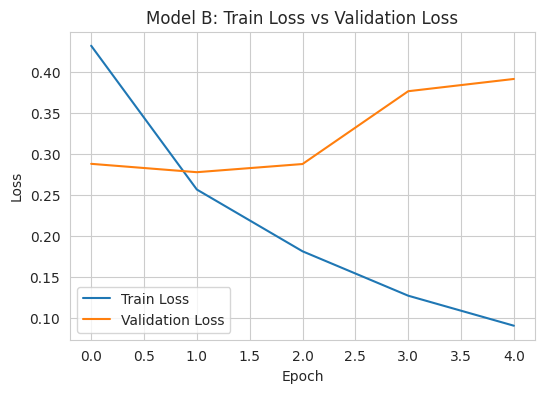

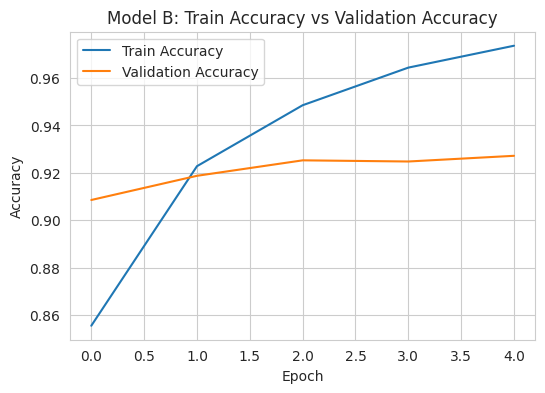

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_B.history['loss'], label='Train Loss')
plt.plot(history_B.history['val_loss'], label='Validation Loss')
plt.title("Model B: Train Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_B.history['accuracy'], label='Train Accuracy')
plt.plot(history_B.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model B: Train Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

* max features 3000/5000/7000/10000 -> 5000 best (10000 better with trade-offs)
* n-gram range (1,1)/(1,2)/(1,3) -> (1,2)
* min df 1/2/3 -> 2
* dense layer 4/5/6 -> 4 (adding dense layers doesn't help)
* defined/uniform/no dropout -> defined

In [ ]:
df = pd.DataFrame(prep_results_val)
df

,Model,Accuracy,Precision,Recall,F1-score
0,A,0.9212,0.9210,0.9212,0.9206
1,B,0.9188,0.9184,0.9188,0.9184


In [ ]:
X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

X_test_dnn = tfidf_A.transform(X_test).astype('float32').toarray()

test_prob_dnn = model_A.predict(X_test_dnn)
test_pred_dnn = np.argmax(test_prob_dnn, axis=1)

test_acc_A = accuracy_score(y_test, test_pred_dnn)
test_f1_A = f1_score(y_test, test_pred_dnn, average='macro')

print("Classification Report: TF-IDF + Deep Neural Network")
print(classification_report(y_test, test_pred_dnn, target_names=le.classes_))

report = classification_report(y_test, test_pred_dnn, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'TF-IDF + DNN',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report: TF-IDF + Deep Neural Network
                        precision    recall  f1-score   support

              Business       0.86      0.89      0.87      3000
Science and Technology       0.86      0.91      0.88      3000
                Sports       0.95      0.96      0.96      3000
            World News       0.95      0.84      0.89      3000

              accuracy                           0.90     12000
             macro avg       0.90      0.90      0.90     12000
          weighted avg       0.90      0.90      0.90     12000



In [ ]:
dnn_pred = pd.DataFrame(test_pred_dnn)
dnn_pred.to_csv("dnn_pred_results.csv", index=False)

### Model: SKIPGRAM + SimpleRNN




In [ ]:
prep_results_val = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

In [ ]:
X_train_text = X_train.astype(str).tolist()
X_val_text   = X_val.astype(str).tolist()
X_test_text  = X_test.astype(str).tolist()

In [ ]:
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq   = tokenizer.texts_to_sequences(X_val_text)
X_test_seq  = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(X_test_seq, maxlen=max_len)

word_index = tokenizer.word_index
vocab_size = min(max_words, len(word_index) + 1)

sentences = [text.split() for text in X_train_text]

embedding_dim = 100

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, i in word_index.items():
    if i < vocab_size:
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_A = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    SimpleRNN(256),
    Dense(128, activation='relu'),
    Dense(len(le.classes_), activation='softmax')
])

model_A.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_A = model_A.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=12,
    batch_size=20,
    callbacks=[early_stop],
    verbose=1
)

val_loss_A, val_acc_A = model_A.evaluate(X_val_pad, y_val, verbose=0)

val_prob_A = model_A.predict(X_val_pad)
val_pred_A = np.argmax(val_prob_A, axis=1)
val_f1_A = f1_score(y_val, val_pred_A, average='macro')

print("SRNN_A Validation Loss:", val_loss_A)
print("SRNN_A Validation Accuracy:", val_acc_A)
print("SRNN_A Validation Macro F1:", val_f1_A)

print("\nSRNN_A Classification Report:")
print(classification_report(y_val, val_pred_A, target_names=le.classes_))

report = classification_report(y_val, val_pred_A, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'A',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/12
4081/4081 ━━━━━━━━━━━━━━━━━━━━ 49s 11ms/step - accuracy: 0.7748 - loss: 0.6277 - val_accuracy: 0.8632 - val_loss: 0.4400
Epoch 2/12
4081/4081 ━━━━━━━━━━━━━━━━━━━━ 48s 12ms/step - accuracy: 0.8330 - loss: 0.5024 - val_accuracy: 0.8787 - val_loss: 0.3848
Epoch 3/12
4081/4081 ━━━━━━━━━━━━━━━━━━━━ 106s 18ms/step - accuracy: 0.8256 - loss: 0.5112 - val_accuracy: 0.8686 - val_loss: 0.4060
Epoch 4/12
4081/4081 ━━━━━━━━━━━━━━━━━━━━ 60s 12ms/step - accuracy: 0.8542 - loss: 0.4333 - val_accuracy: 0.8644 - val_loss: 0.4160
Epoch 5/12
4081/4081 ━━━━━━━━━━━━━━━━━━━━ 50s 12ms/step - accuracy: 0.8179 - loss: 0.5242 - val_accuracy: 0.8277 - val_loss: 0.4906
638/638 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
SRNN_A Validation Loss: 0.3848247826099396
SRNN_A Validation Accuracy: 0.8786824345588684
SRNN_A Validation Macro F1: 0.8747361691384843

SRNN_A Classification Report:
                        precision    recall  f1-score   support

              Business       0.86      0.81      0.83      5367
S

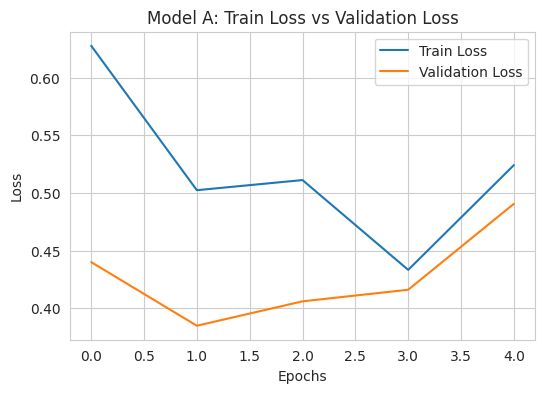

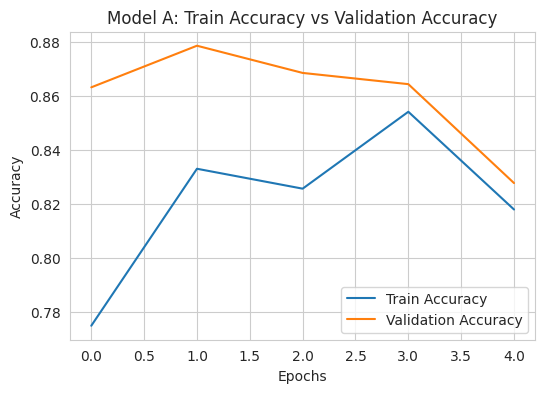

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_A.history['loss'], label='Train Loss')
plt.plot(history_A.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model A: Train Loss vs Validation Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_A.history['accuracy'], label='Train Accuracy')
plt.plot(history_A.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model A: Train Accuracy vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_B = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    SimpleRNN(128, dropout=0.3, recurrent_dropout=0.3),

    Dense(96, activation='tanh'),
    Dropout(0.50),

    Dense(64, activation='tanh'),
    Dropout(0.40),

    Dense(len(le.classes_), activation='softmax')
])

model_B.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_B = model_B.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

val_loss_B, val_acc_B = model_B.evaluate(X_val_pad, y_val, verbose=0)

val_prob_B = model_B.predict(X_val_pad)
val_pred_B = np.argmax(val_prob_B, axis=1)
val_f1_B = f1_score(y_val, val_pred_B, average='macro')

print("SRNN_B Validation Loss:", val_loss_B)
print("SRNN_B Validation Accuracy:", val_acc_B)
print("SRNN_B Validation Macro F1:", val_f1_B)

print("\nSRNN_B Classification Report:")
print(classification_report(y_val, val_pred_B, target_names=le.classes_))

report = classification_report(y_val, val_pred_B, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'B',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/15
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 34s 11ms/step - accuracy: 0.6615 - loss: 0.8640 - val_accuracy: 0.7804 - val_loss: 0.6144
Epoch 2/15
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7186 - loss: 0.7514 - val_accuracy: 0.8270 - val_loss: 0.4940
Epoch 3/15
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7122 - loss: 0.7719 - val_accuracy: 0.8099 - val_loss: 0.5568
Epoch 4/15
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7145 - loss: 0.7721 - val_accuracy: 0.8015 - val_loss: 0.5771
Epoch 5/15
2551/2551 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7449 - loss: 0.7201 - val_accuracy: 0.8223 - val_loss: 0.5297
638/638 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
SRNN_B Validation Loss: 0.4939784109592438
SRNN_B Validation Accuracy: 0.8270182609558105
SRNN_B Validation Macro F1: 0.8226002013825624

SRNN_B Classification Report:
                        precision    recall  f1-score   support

              Business       0.78      0.72      0.75      5367
Sc

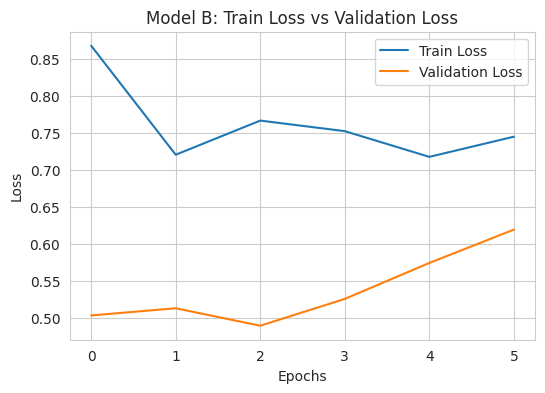

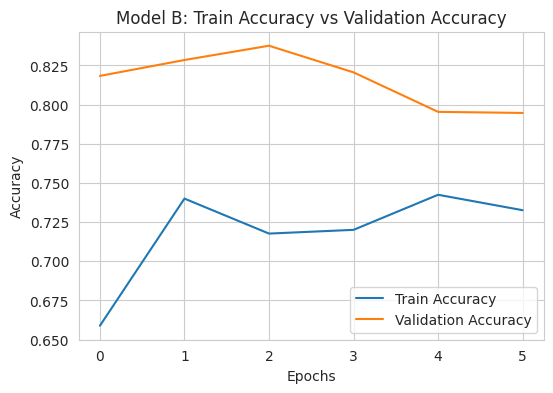

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_B.history['loss'], label='Train Loss')
plt.plot(history_B.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model B: Train Loss vs Validation Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_B.history['accuracy'], label='Train Accuracy')
plt.plot(history_B.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model B: Train Accuracy vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

model_C = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    SimpleRNN(
        128,
        activation='tanh',
        dropout=0.1,
        recurrent_dropout=0.1,
        return_sequences=False
    ),

    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(len(le.classes_), activation='softmax')
])

model_C.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_C = model_C.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

val_loss_C, val_acc_C = model_C.evaluate(X_val_pad, y_val, verbose=0)

val_proC_C = model_C.predict(X_val_pad)
val_pred_C = np.argmax(val_proC_C, axis=1)
val_f1_C = f1_score(y_val, val_pred_C, average='macro')

print("SRNN_C Validation Loss:", val_loss_C)
print("SRNN_C Validation Accuracy:", val_acc_C)
print("SRNN_C Validation Macro F1:", val_f1_C)

print("\nSRNN_C Classification Report:")
print(classification_report(y_val, val_pred_C, target_names=le.classes_))

report = classification_report(y_val, val_pred_C, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'C',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

Epoch 1/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.7783 - loss: 0.6165 - val_accuracy: 0.8647 - val_loss: 0.4189
Epoch 2/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8182 - loss: 0.5366 - val_accuracy: 0.8646 - val_loss: 0.4100
Epoch 3/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8301 - loss: 0.5071 - val_accuracy: 0.8550 - val_loss: 0.4281
Epoch 4/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8432 - loss: 0.4745 - val_accuracy: 0.8803 - val_loss: 0.3673
Epoch 5/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8421 - loss: 0.4800 - val_accuracy: 0.8696 - val_loss: 0.3981
Epoch 6/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8317 - loss: 0.5017 - val_accuracy: 0.8736 - val_loss: 0.3933
Epoch 7/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.8380 - loss: 0.4848 - val_accuracy: 0.8705 - val_loss: 0.4034
Epoch 8/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.8364 -

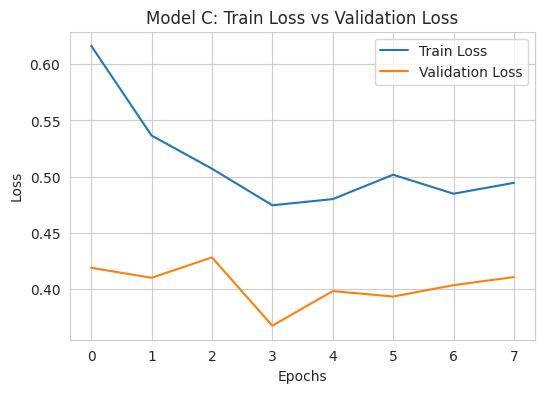

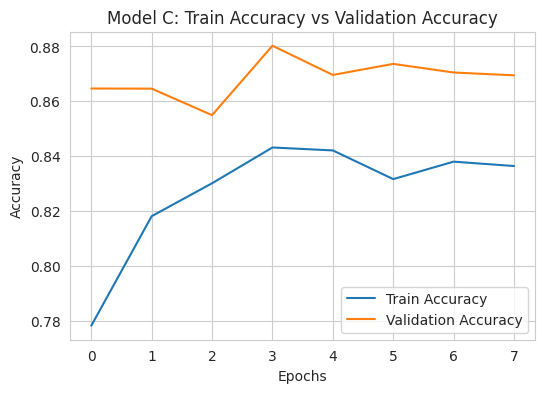

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_C.history['loss'], label='Train Loss')
plt.plot(history_C.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model C: Train Loss vs Validation Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_C.history['accuracy'], label='Train Accuracy')
plt.plot(history_C.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model C: Train Accuracy vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
df = pd.DataFrame(prep_results_val)
df

,Model,Accuracy,Precision,Recall,F1-score
0,A,0.8787,0.8785,0.8787,0.8778
1,B,0.8376,0.8371,0.8376,0.8370
2,C,0.8803,0.8798,0.8803,0.8794


In [ ]:
y_test_pred = model_C.predict(X_test_pad).argmax(axis=1)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1  = f1_score(y_test, y_test_pred, average='macro')

print("Classification Report: Skipgram + SimpleRNN")
print(classification_report(y_test, y_test_pred, target_names=le.classes_))

srnn_report = classification_report(y_test, y_test_pred, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + SimpleRNN',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Classification Report: Skipgram + SimpleRNN
                        precision    recall  f1-score   support

              Business       0.88      0.80      0.84      3000
Science and Technology       0.79      0.92      0.85      3000
                Sports       0.94      0.96      0.95      3000
            World News       0.91      0.84      0.87      3000

              accuracy                           0.88     12000
             macro avg       0.88      0.88      0.88     12000
          weighted avg       0.88      0.88      0.88     12000



In [ ]:
srnn_pred = pd.DataFrame(y_pred_srnn)
srnn_pred.to_csv("srnn_pred_results.csv", index=False)

### Model: SKIPGRAM + GRU


In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

In [ ]:
X_train_text = X_train.astype(str).tolist()
X_val_text   = X_val.astype(str).tolist()
X_test_text  = X_test.astype(str).tolist()

In [ ]:
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq   = tokenizer.texts_to_sequences(X_val_text)
X_test_seq  = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(X_test_seq, maxlen=max_len)

word_index = tokenizer.word_index
vocab_size = min(max_words, len(word_index) + 1)

sentences = [text.split() for text in X_train_text]

embedding_dim = 100

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, i in word_index.items():
    if i < vocab_size:
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_GRU = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    GRU(128, dropout=0.3, recurrent_dropout=0.3),

    Dense(96, activation='tanh'),
    Dropout(0.5),

    Dense(64, activation='tanh'),
    Dropout(0.4),

    Dense(len(le.classes_), activation='softmax')
])

model_GRU.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_GRU = model_GRU.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 431s 333ms/step - accuracy: 0.8234 - loss: 0.4998 - val_accuracy: 0.8900 - val_loss: 0.3179
Epoch 2/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 383s 300ms/step - accuracy: 0.8728 - loss: 0.3781 - val_accuracy: 0.8966 - val_loss: 0.2998
Epoch 3/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 370s 290ms/step - accuracy: 0.8836 - loss: 0.3453 - val_accuracy: 0.9023 - val_loss: 0.2855
Epoch 4/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 369s 289ms/step - accuracy: 0.8900 - loss: 0.3255 - val_accuracy: 0.9064 - val_loss: 0.2731
Epoch 5/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 368s 288ms/step - accuracy: 0.8951 - loss: 0.3113 - val_accuracy: 0.9103 - val_loss: 0.2648
Epoch 6/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 366s 287ms/step - accuracy: 0.8984 - loss: 0.3020 - val_accuracy: 0.9122 - val_loss: 0.2583
Epoch 7/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 367s 288ms/step - accuracy: 0.9024 - loss: 0.2923 - val_accuracy: 0.9149 - val_loss: 0.2526
Epoch 8/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 381s 287ms/step - ac

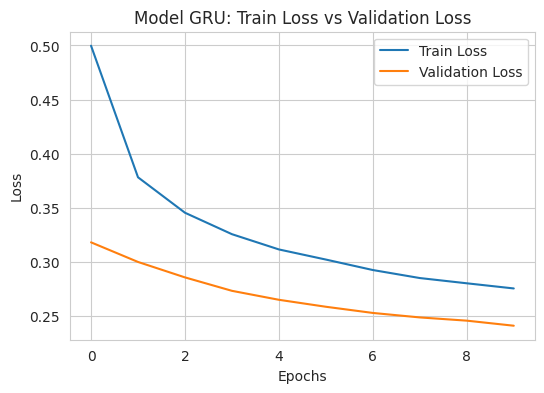

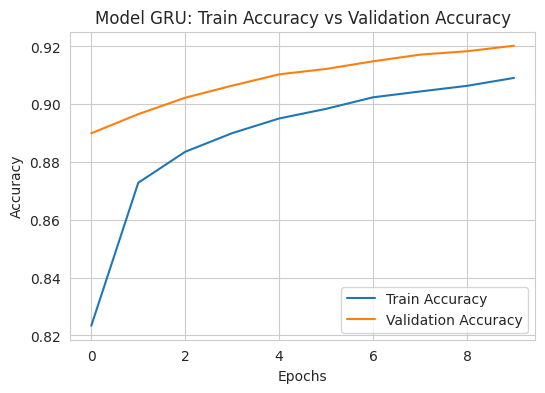

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_GRU.history['loss'], label='Train Loss')
plt.plot(history_GRU.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model GRU: Train Loss vs Validation Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_GRU.history['accuracy'], label='Train Accuracy')
plt.plot(history_GRU.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model GRU: Train Accuracy vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
y_pred_GRU = model_GRU.predict(X_test_pad).argmax(axis=1)

test_acc_GRU = accuracy_score(y_test, y_pred_GRU)
test_f1_GRU = f1_score(y_test, y_pred_GRU, average='macro')

print("\nClassification Report: Skipgram + GRU")
print(classification_report(y_test, y_pred_GRU))

report = classification_report(y_test, y_test_pred_GRU, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + GRU',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step

Classification Report: Skipgram + GRU
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      3000
           1       0.86      0.94      0.90      3000
           2       0.95      0.98      0.96      3000
           3       0.96      0.87      0.91      3000

    accuracy                           0.91     12000
   macro avg       0.92      0.91      0.91     12000
weighted avg       0.92      0.91      0.91     12000



In [ ]:
gru_pred = pd.DataFrame(y_pred_GRU)
gru_pred.to_csv("gru_pred_results.csv", index=False)

### Model: SKIPGRAM + LSTM


In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_LSTM = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    LSTM(
        128,
        dropout=0.2,
        recurrent_dropout=0.2
    ),

    BatchNormalization(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(len(le.classes_), activation='softmax')
])

model_LSTM.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_LSTM = model_LSTM.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 399s 309ms/step - accuracy: 0.8611 - loss: 0.4089 - val_accuracy: 0.8969 - val_loss: 0.2992
Epoch 2/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 442s 310ms/step - accuracy: 0.8894 - loss: 0.3239 - val_accuracy: 0.9045 - val_loss: 0.2752
Epoch 3/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 387s 303ms/step - accuracy: 0.9000 - loss: 0.2963 - val_accuracy: 0.9073 - val_loss: 0.2673
Epoch 4/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 390s 306ms/step - accuracy: 0.9048 - loss: 0.2772 - val_accuracy: 0.9131 - val_loss: 0.2531
Epoch 5/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 391s 306ms/step - accuracy: 0.9097 - loss: 0.2648 - val_accuracy: 0.9163 - val_loss: 0.2429
Epoch 6/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 389s 305ms/step - accuracy: 0.9135 - loss: 0.2519 - val_accuracy: 0.9198 - val_loss: 0.2337
Epoch 7/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 383s 300ms/step - accuracy: 0.9161 - loss: 0.2434 - val_accuracy: 0.9213 - val_loss: 0.2293
Epoch 8/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 383s 300ms/step - ac

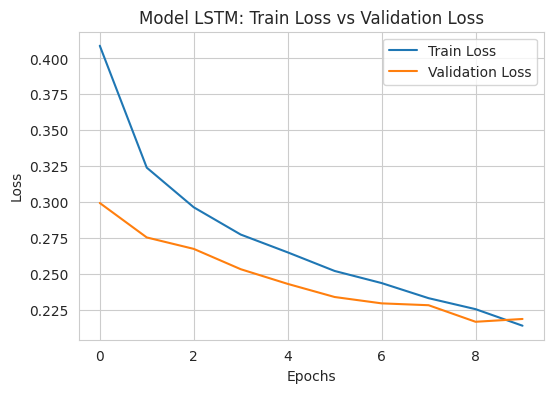

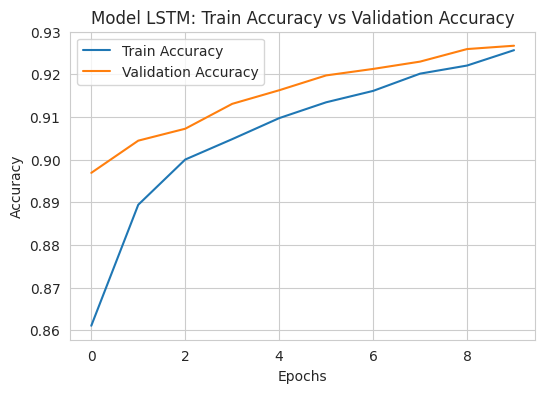

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_LSTM.history['loss'], label='Train Loss')
plt.plot(history_LSTM.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model LSTM: Train Loss vs Validation Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history_LSTM.history['accuracy'], label='Train Accuracy')
plt.plot(history_LSTM.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model LSTM: Train Accuracy vs Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
y_pred_LSTM = model_LSTM.predict(X_test_pad).argmax(axis=1)

test_acc_LSTM = accuracy_score(y_test, y_pred_LSTM)
test_f1_LSTM = f1_score(y_test, y_pred_LSTM, average='macro')

print("\nClassification Report: Skipgram + LSTM")
print(classification_report(y_test, y_pred_LSTM))

report = classification_report(y_test, y_test_pred_LSTM, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + LSTM',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step

Classification Report: Skipgram + LSTM
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      3000
           1       0.85      0.96      0.90      3000
           2       0.95      0.98      0.97      3000
           3       0.96      0.85      0.90      3000

    accuracy                           0.91     12000
   macro avg       0.92      0.91      0.91     12000
weighted avg       0.92      0.91      0.91     12000



In [ ]:
lstm_pred = pd.DataFrame(y_pred_LSTM)
lstm_pred.to_csv("lstm_pred_results.csv", index=False)

### Model: SKIPGRAM + Bidirectional SimpleRNN

In [ ]:
prep_results_val = []

In [ ]:
X_train, X_val, y_train, y_val = make_train_val_split(train_optimum)

X_test = test_optimum["processed_text"]
y_test = test_optimum["label"]

In [ ]:
X_train_text = X_train.astype(str).tolist()
X_val_text   = X_val.astype(str).tolist()
X_test_text  = X_test.astype(str).tolist()

In [ ]:
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq   = tokenizer.texts_to_sequences(X_val_text)
X_test_seq  = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(X_test_seq, maxlen=max_len)

word_index = tokenizer.word_index
vocab_size = min(max_words, len(word_index) + 1)

sentences = [text.split() for text in X_train_text]

embedding_dim = 100

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=embedding_dim,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, i in word_index.items():
    if i < vocab_size:
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

model_b_srnn1 = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(SimpleRNN(256, dropout=0.2, recurrent_dropout=0.2)),

    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(len(le.classes_), activation='softmax')
])

model_b_srnn1.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_b_srnn1 = model_b_srnn1.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.7311 - loss: 0.7328 - val_accuracy: 0.8256 - val_loss: 0.4945
Epoch 2/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.7751 - loss: 0.6333 - val_accuracy: 0.8558 - val_loss: 0.4602
Epoch 3/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.7925 - loss: 0.5985 - val_accuracy: 0.8616 - val_loss: 0.4290
Epoch 4/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.7985 - loss: 0.5820 - val_accuracy: 0.8507 - val_loss: 0.4416
Epoch 5/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8213 - loss: 0.5306 - val_accuracy: 0.8728 - val_loss: 0.3869
Epoch 6/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8354 - loss: 0.4972 - val_accuracy: 0.8659 - val_loss: 0.4035
Epoch 7/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8354 - loss: 0.4884 - val_accuracy: 0.8734 - val_loss: 0.3797
Epoch 8/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.8419 -

In [ ]:
y_pred_b_srnn1 = model_b_srnn1.predict(X_val_pad).argmax(axis=1)

acc_b_srnn1 = accuracy_score(y_val, y_pred_b_srnn1)
f1_b_srnn1 = f1_score(y_val, y_pred_b_srnn1, average='macro')

print("bi_SRNN Accuracy:", acc_b_srnn1)
print("bi_SRNN Macro F1:", f1_b_srnn1)

print("\nClassification Report: Skipgram + Bidirectional SimpleRNN")
print(classification_report(y_val, y_pred_b_srnn1, target_names=le.classes_))

report = classification_report(y_val, y_pred_b_srnn1, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'Skipgram + Bidirectional SimpleRNN',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

638/638 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step
bi_SRNN Accuracy: 0.8724082152835645
bi_SRNN Macro F1: 0.8688599929105587

Classification Report: Skipgram + Bidirectional SimpleRNN
                        precision    recall  f1-score   support

              Business       0.87      0.76      0.81      5367
Science and Technology       0.85      0.93      0.89      8792
                Sports       0.93      0.94      0.94      3658
            World News       0.87      0.80      0.84      2584

              accuracy                           0.87     20401
             macro avg       0.88      0.86      0.87     20401
          weighted avg       0.87      0.87      0.87     20401



In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

model_b_srnn2 = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(SimpleRNN(256, dropout=0.3, recurrent_dropout=0.3)),

    Dense(128, activation='relu'),
    Dropout(0.4),

    Dense(len(le.classes_), activation='softmax')
])

model_b_srnn2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_b_srnn2 = model_b_srnn2.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.6854 - loss: 0.8094 - val_accuracy: 0.8236 - val_loss: 0.5000
Epoch 2/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.7647 - loss: 0.6517 - val_accuracy: 0.8430 - val_loss: 0.4590
Epoch 3/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.7871 - loss: 0.6046 - val_accuracy: 0.8107 - val_loss: 0.4978
Epoch 4/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.7640 - loss: 0.6583 - val_accuracy: 0.8537 - val_loss: 0.4247
Epoch 5/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.7849 - loss: 0.6175 - val_accuracy: 0.8672 - val_loss: 0.4127
Epoch 6/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.8032 - loss: 0.5758 - val_accuracy: 0.8501 - val_loss: 0.4399
Epoch 7/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.8073 - loss: 0.5601 - val_accuracy: 0.8674 - val_loss: 0.4016
Epoch 8/20
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.8038 -

In [ ]:
y_pred_b_srnn2 = model_b_srnn2.predict(X_val_pad).argmax(axis=1)

acc_b_srnn2 = accuracy_score(y_val, y_pred_b_srnn2)
f1_b_srnn2 = f1_score(y_val, y_pred_b_srnn2, average='macro')

print("b_srnn2 - validation Accuracy:", acc_b_srnn2)
print("b_srnn2 - validation Macro F1:", f1_b_srnn2)

print("\nClassification Report: Skipgram + Bidirectional SimpleRNN")
print(classification_report(y_val, y_pred_b_srnn2, target_names=le.classes_))

report = classification_report(y_val, y_pred_b_srnn2, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_val.append({
    'Model': 'Skipgram + Bidirectional SimpleRNN',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

638/638 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
b_srnn2 - validation Accuracy: 0.8712318023626293
b_srnn2 - validation Macro F1: 0.8675939864101192

Classification Report: Skipgram + Bidirectional SimpleRNN
                        precision    recall  f1-score   support

              Business       0.84      0.80      0.82      5367
Science and Technology       0.87      0.90      0.89      8792
                Sports       0.92      0.95      0.93      3658
            World News       0.87      0.79      0.83      2584

              accuracy                           0.87     20401
             macro avg       0.87      0.86      0.87     20401
          weighted avg       0.87      0.87      0.87     20401



In [ ]:
df = pd.DataFrame(prep_results_val)
df

,Model,Accuracy,Precision,Recall,F1-score
0,Skipgram + Bidirectional SimpleRNN,0.8782,0.8776,0.8782,0.8776
1,Skipgram + Bidirectional SimpleRNN,0.8712,0.8706,0.8712,0.8704


In [ ]:
y_pred_b_srnn = model_b_srnn1.predict(X_test_pad).argmax(axis=1)

test_acc_b_srnn = accuracy_score(y_test, y_pred_b_srnn)
test_f1_b_srnn = f1_score(y_test, y_pred_b_srnn, average='macro')

print("Classification Report: Skipgram + Bidirectional SimpleRNN")
print(classification_report(y_test, y_pred_b_srnn, target_names=le.classes_))

report = classification_report(y_test, y_pred_b_srnn, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + Bidirectional SimpleRNN',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Classification Report: Skipgram + Bidirectional SimpleRNN
                        precision    recall  f1-score   support

              Business       0.87      0.77      0.81      3000
Science and Technology       0.74      0.93      0.82      3000
                Sports       0.94      0.94      0.94      3000
            World News       0.94      0.80      0.86      3000

              accuracy                           0.86     12000
             macro avg       0.87      0.86      0.86     12000
          weighted avg       0.87      0.86      0.86     12000



In [ ]:
b_srnn_pred = pd.DataFrame(y_pred_b_srnn)
b_srnn_pred.to_csv("b_srnn_pred_results.csv", index=False)

### Model: SKIPGRAM + Bidirectional GRU

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_bGRU = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(GRU(128, dropout=0.3, recurrent_dropout=0.3)),

    Dense(96, activation='tanh'),
    Dropout(0.5),

    Dense(64, activation='tanh'),
    Dropout(0.4),

    Dense(len(le.classes_), activation='softmax')
])

model_bGRU.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_bGRU = model_bGRU.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 731s 565ms/step - accuracy: 0.8187 - loss: 0.5078 - val_accuracy: 0.8905 - val_loss: 0.3207
Epoch 2/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 708s 555ms/step - accuracy: 0.8727 - loss: 0.3769 - val_accuracy: 0.8996 - val_loss: 0.2979
Epoch 3/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 745s 557ms/step - accuracy: 0.8825 - loss: 0.3464 - val_accuracy: 0.9031 - val_loss: 0.2835
Epoch 4/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 701s 550ms/step - accuracy: 0.8886 - loss: 0.3283 - val_accuracy: 0.9055 - val_loss: 0.2749
Epoch 5/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 743s 550ms/step - accuracy: 0.8937 - loss: 0.3143 - val_accuracy: 0.9090 - val_loss: 0.2648
Epoch 6/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 699s 548ms/step - accuracy: 0.8976 - loss: 0.3023 - val_accuracy: 0.9102 - val_loss: 0.2617
Epoch 7/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 705s 553ms/step - accuracy: 0.9011 - loss: 0.2946 - val_accuracy: 0.9150 - val_loss: 0.2526
Epoch 8/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 700s 548ms/step - ac

In [ ]:
y_pred_bGRU = model_bGRU.predict(X_test_pad).argmax(axis=1)

acc_bGRU = accuracy_score(y_test, y_pred_bGRU)
f1_bGRU = f1_score(y_test, y_pred_bGRU, average='macro')

print("bGRU - validation Accuracy:", acc_bGRU)
print("bGRU - validation Macro F1:", f1_bGRU)

print("\nClassification Report: Skipgram + Bidirectional GRU")
print(classification_report(y_test, y_pred_bGRU))

report = classification_report(y_test, y_pred_bGRU, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + Bidirectional GRU',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 77s 204ms/step
bGRU - validation Accuracy: 0.9115
bGRU - validation Macro F1: 0.9113683885319401

Classification Report: Skipgram + Bidirectional GRU
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      3000
           1       0.86      0.94      0.90      3000
           2       0.95      0.98      0.96      3000
           3       0.96      0.85      0.90      3000

    accuracy                           0.91     12000
   macro avg       0.91      0.91      0.91     12000
weighted avg       0.91      0.91      0.91     12000



In [ ]:
b_gru_pred = pd.DataFrame(y_pred_bGRU)
b_gru_pred.to_csv("b_gru_pred_results.csv", index=False)

### Model: SKIPGRAM + Bidirectional LSTM

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_bLSTM = Sequential([
    tf.keras.Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ),

    Bidirectional(LSTM(128, dropout=0.2, recurrent_dropout=0.2)),

    BatchNormalization(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(len(le.classes_), activation='softmax')
])

model_bLSTM.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_bLSTM = model_bLSTM.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 826s 641ms/step - accuracy: 0.8618 - loss: 0.4051 - val_accuracy: 0.8998 - val_loss: 0.2914
Epoch 2/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 818s 641ms/step - accuracy: 0.8901 - loss: 0.3225 - val_accuracy: 0.9073 - val_loss: 0.2673
Epoch 3/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 888s 661ms/step - accuracy: 0.8997 - loss: 0.2951 - val_accuracy: 0.9124 - val_loss: 0.2541
Epoch 4/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 845s 662ms/step - accuracy: 0.9051 - loss: 0.2772 - val_accuracy: 0.9172 - val_loss: 0.2409
Epoch 5/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 811s 635ms/step - accuracy: 0.9109 - loss: 0.2623 - val_accuracy: 0.9200 - val_loss: 0.2351
Epoch 6/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 805s 631ms/step - accuracy: 0.9129 - loss: 0.2505 - val_accuracy: 0.9226 - val_loss: 0.2273
Epoch 7/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 851s 622ms/step - accuracy: 0.9188 - loss: 0.2372 - val_accuracy: 0.9252 - val_loss: 0.2235
Epoch 8/10
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 807s 626ms/step - ac

In [ ]:
y_pred_bLSTM = model_bLSTM.predict(X_test_pad).argmax(axis=1)

acc_bLSTM = accuracy_score(y_test, y_pred_bLSTM)
f1_bLSTM = f1_score(y_test, y_pred_bLSTM, average='macro')

print("\nClassification Report: Skipgram + Bidirectional LSTM")
print(classification_report(y_test, y_pred_bLSTM))

report = classification_report(y_test, y_pred_bLSTM, target_names=le.classes_, output_dict=True)
acc = round(report['accuracy'], 4)
precision = round(report['weighted avg']['precision'], 4)
recall = round(report['weighted avg']['recall'], 4)
f1 = round(report['weighted avg']['f1-score'], 4)
prep_results_test.append({
    'Model': 'Skipgram + Bidirectional LSTM',
    'Accuracy': acc,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
})

375/375 ━━━━━━━━━━━━━━━━━━━━ 84s 223ms/step

Classification Report: Skipgram + Bidirectional LSTM
              precision    recall  f1-score   support

           0       0.91      0.86      0.89      3000
           1       0.84      0.96      0.90      3000
           2       0.97      0.98      0.97      3000
           3       0.96      0.87      0.91      3000

    accuracy                           0.92     12000
   macro avg       0.92      0.92      0.92     12000
weighted avg       0.92      0.92      0.92     12000



In [ ]:
b_lstm_pred = pd.DataFrame(y_pred_bLSTM)
b_lstm_pred.to_csv("b_lstm_pred_results.csv", index=False)

### Model Evaluation

In [ ]:
print(prep_results_test)

[{'Model': 'TF-IDF + LOGISTIC REGRESSION', 'Accuracy': 0.9328, 'Precision': 0.9329, 'Recall': 0.9328, 'F1-score': 0.9324}, {'Model': 'TF-IDF + DNN', 'Accuracy': 0.9221, 'Precision': 0.9222, 'Recall': 0.9221, 'F1-score': 0.9214}, {'Model': 'Skipgram + SimpleRNN', 'Accuracy': 0.8803, 'Precision': 0.8798, 'Recall': 0.8803, 'F1-score': 0.8794}, {'Model': 'Skipgram + GRU', 'Accuracy': 0.9135, 'Precision': 0.9156, 'Recall': 0.9135, 'F1-score': 0.9134}, {'Model': 'Skipgram + LSTM', 'Accuracy': 0.9135, 'Precision': 0.9156, 'Recall': 0.9135, 'F1-score': 0.9134}, {'Model': 'Skipgram + Bidirectional SimpleRNN', 'Accuracy': 0.8737, 'Precision': 0.8806, 'Recall': 0.8737, 'F1-score': 0.8739}, {'Model': 'Skipgram + Bidirectional GRU', 'Accuracy': 0.9115, 'Precision': 0.914, 'Recall': 0.9115, 'F1-score': 0.9114}, {'Model': 'Skipgram + Bidirectional LSTM', 'Accuracy': 0.9171, 'Precision': 0.9207, 'Recall': 0.9171, 'F1-score': 0.9171}]


In [ ]:
prep_results_test = [
    {'Model': 'TF-IDF + LOGISTIC REGRESSION', 'Accuracy': 0.9328, 'Precision': 0.9329, 'Recall': 0.9328, 'F1-score': 0.9324},
    {'Model': 'TF-IDF + DNN', 'Accuracy': 0.9221, 'Precision': 0.9222, 'Recall': 0.9221, 'F1-score': 0.9214},
    {'Model': 'Skipgram + SimpleRNN', 'Accuracy': 0.8803, 'Precision': 0.8798, 'Recall': 0.8803, 'F1-score': 0.8794},
    {'Model': 'Skipgram + GRU', 'Accuracy': 0.9135, 'Precision': 0.9156, 'Recall': 0.9135, 'F1-score': 0.9134},
    {'Model': 'Skipgram + LSTM', 'Accuracy': 0.9135, 'Precision': 0.9156, 'Recall': 0.9135, 'F1-score': 0.9134},
    {'Model': 'Skipgram + Bidirectional SimpleRNN', 'Accuracy': 0.8737, 'Precision': 0.8806, 'Recall': 0.8737, 'F1-score': 0.8739},
    {'Model': 'Skipgram + Bidirectional GRU', 'Accuracy': 0.9115, 'Precision': 0.914, 'Recall': 0.9115, 'F1-score': 0.9114},
    {'Model': 'Skipgram + Bidirectional LSTM', 'Accuracy': 0.9171, 'Precision': 0.9207, 'Recall': 0.9171, 'F1-score': 0.9171}
 ]

In [ ]:
models = [
    'LR',
    'DNN',
    'RNN',
    'GRU',
    'LSTM',
    'Bi-RNN',
    'Bi-GRU',
    'Bi-LSTM'
]

In [ ]:
df = pd.DataFrame(prep_results_test)

In [ ]:
df['Model'] = models

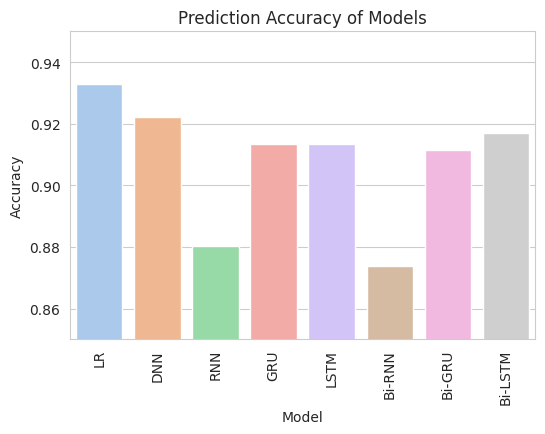

In [ ]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=df,
    palette='pastel'
)

plt.ylim(0.85, 0.95)
plt.title('Prediction Accuracy of Models')
plt.xticks(rotation=90)
plt.show()

In [ ]:
models = df['Model'].tolist()
precisions = df['Precision'].tolist()
recalls = df['Recall'].tolist()
f1_scores = df['F1-score'].tolist()

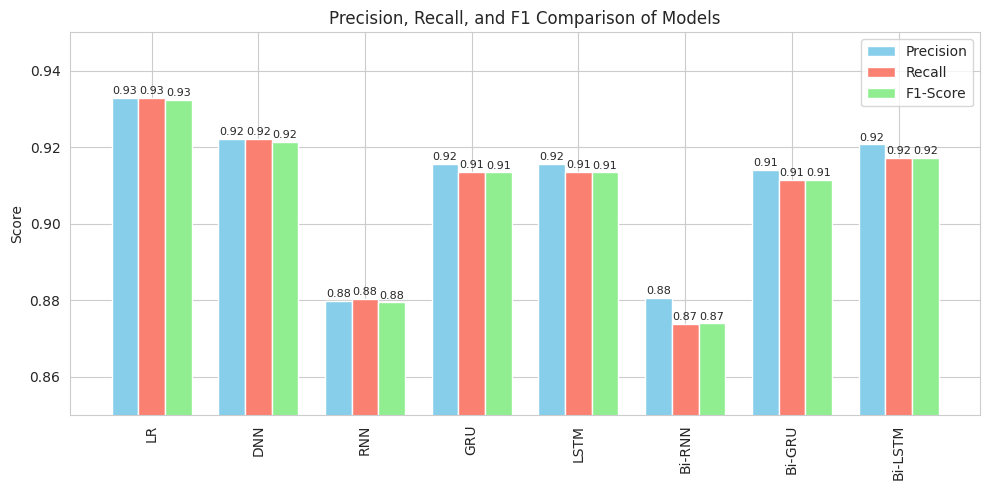

In [ ]:
x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10,5))

plt.bar(x - width, precisions, width, label='Precision', color='skyblue')
plt.bar(x, recalls, width, label='Recall', color='salmon')
plt.bar(x + width, f1_scores, width, label='F1-Score', color='lightgreen')

plt.xticks(x, models, rotation=90)
plt.ylim(0.85, 0.95)
plt.ylabel('Score')
plt.title('Precision, Recall, and F1 Comparison of Models')
plt.legend()

for i in range(len(models)):
    plt.text(i - width, precisions[i] + 0.001, f"{precisions[i]:.2f}", ha='center', fontsize=8)
    plt.text(i, recalls[i] + 0.001, f"{recalls[i]:.2f}", ha='center', fontsize=8)
    plt.text(i + width, f1_scores[i] + 0.001, f"{f1_scores[i]:.2f}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
lr_pred = pd.read_csv('/content/lr_pred_results.csv')
dnn_pred = pd.read_csv('/content/dnn_pred_results.csv')
srnn_pred = pd.read_csv('/content/srnn_pred_results.csv')
gru_pred = pd.read_csv('/content/gru_pred_results.csv')
lstm_pred = pd.read_csv('/content/lstm_pred_results.csv')
b_srnn_pred = pd.read_csv('/content/b_srnn_pred_results.csv')
b_gru_pred = pd.read_csv('/content/b_gru_pred_results.csv')
b_lstm_pred = pd.read_csv('/content/b_lstm_pred_results.csv')

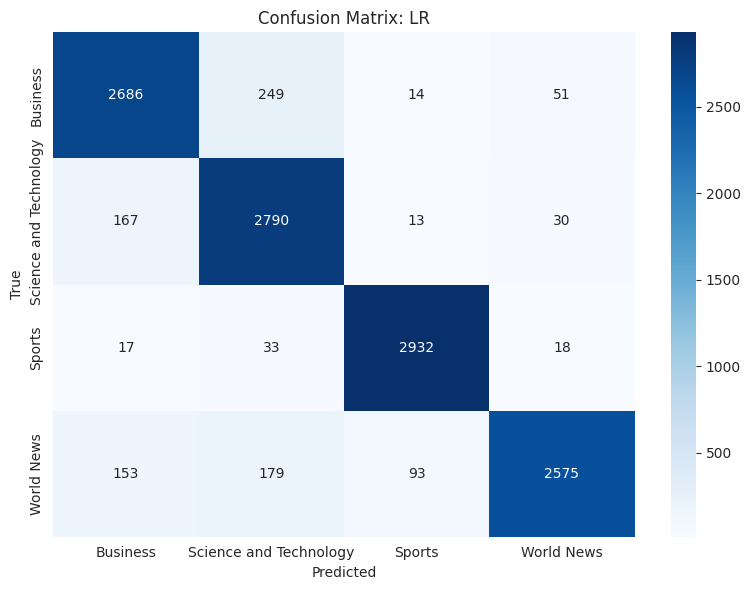

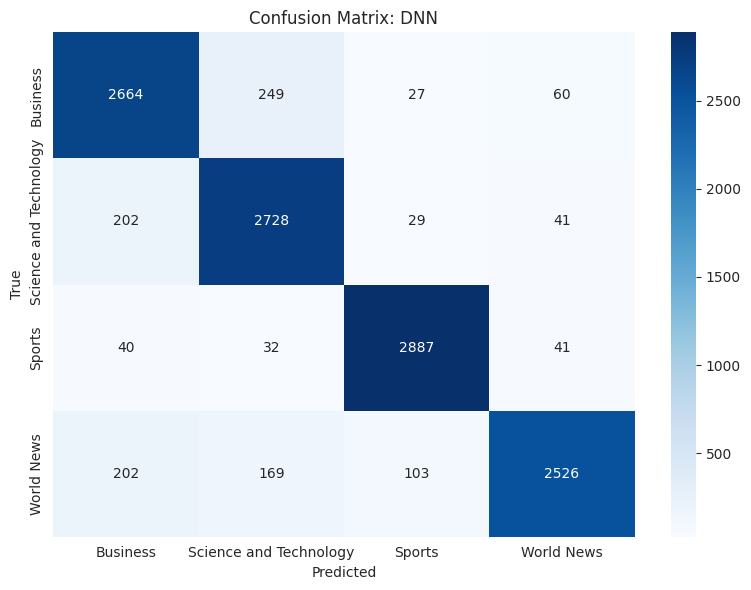

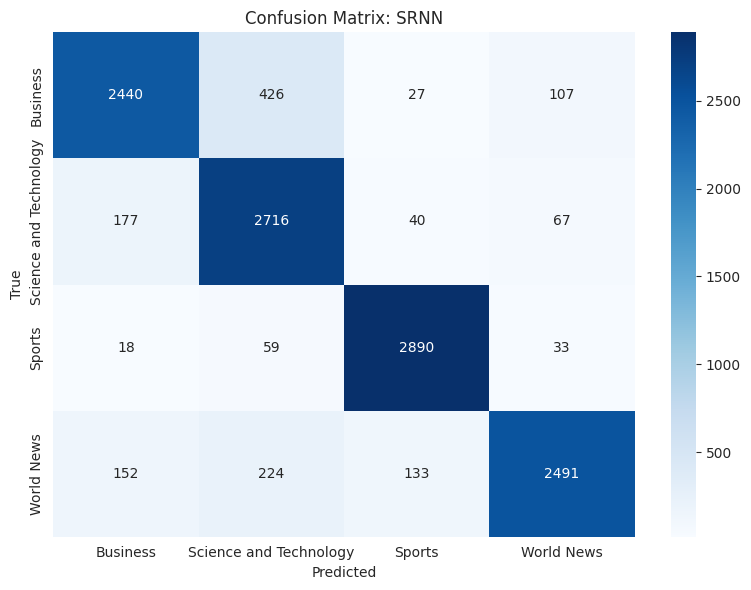

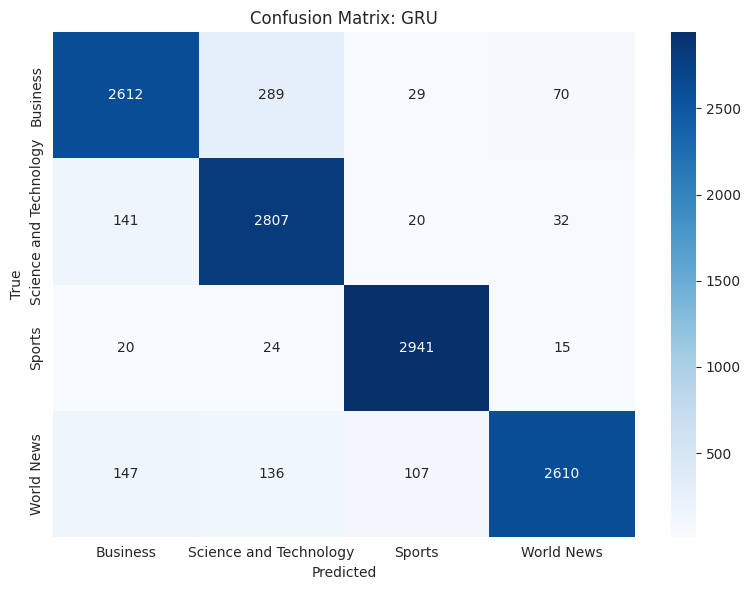

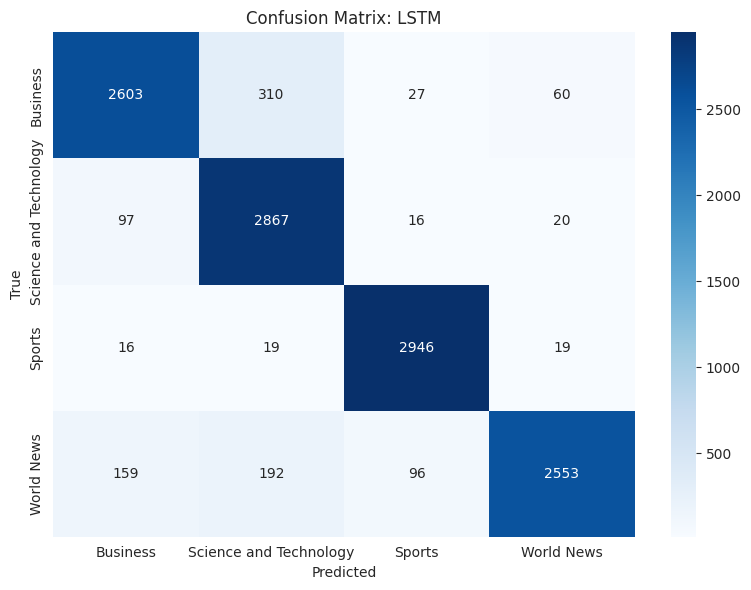

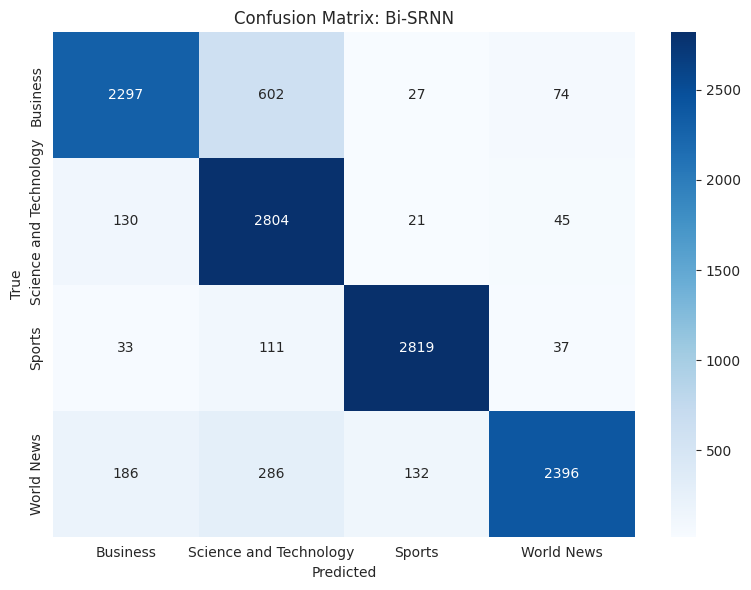

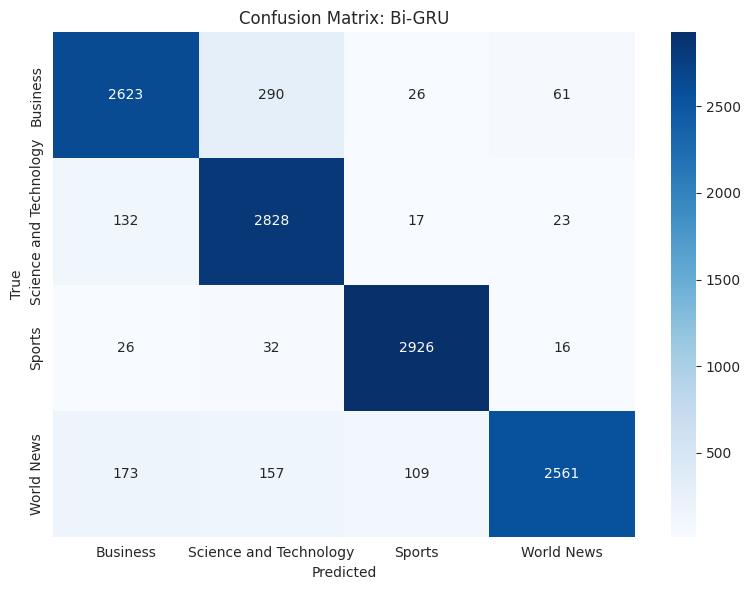

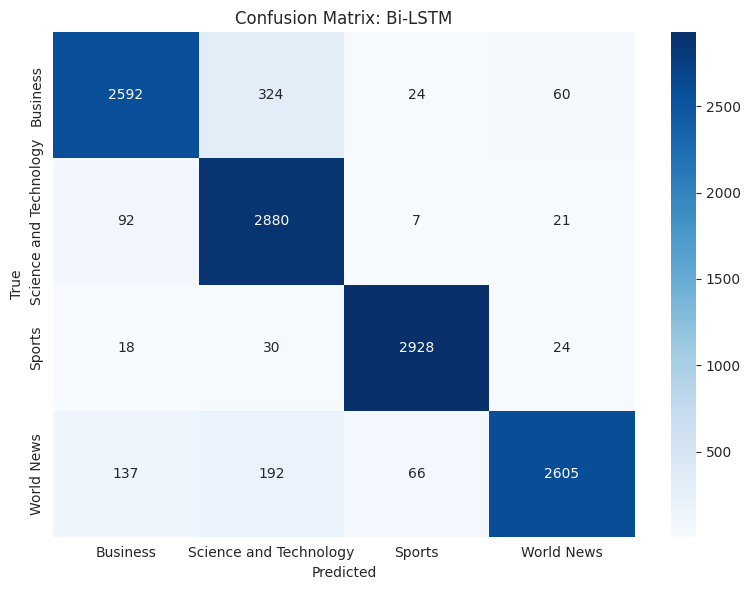

In [ ]:
predictions = {
    "LR": lr_pred,
    "DNN": dnn_pred,
    "SRNN": srnn_pred,
    "GRU": gru_pred,
    "LSTM": lstm_pred,
    "Bi-SRNN": b_srnn_pred,
    "Bi-GRU": b_gru_pred,
    "Bi-LSTM": b_lstm_pred
}

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )

    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.tight_layout()
    plt.show()

Observations:

* Best performance: TF-IDF + Logistic Regression -> Accuracy: 93.28% (highest), balanced precision/recall/F1 score.
* A simple linear model like Logistic Regression combined with TF-IDF is efficient for the dataset, which means the dataset is probably linearly separable, even without using complex NN models.
* Worst performance: Skipgram + SimpleRNN -> Accuracy: 88.03%, Skipgram + Bidirectional SimpleRNN -> Accuracy: 87.37%, complex structure, time-inefficient, unable to understand patterns accurately.
* GRU / LSTM handles sequence dependencies better, stores important context better, by avoiding vanishing gradient problem. Results get significantly better than RNN, reaching 91.35%.
* Bidirectional LSTM: 91.71% > LSTM: 91.35%, Bidirectional GRU: 91.15% < GRU: 91.35%, slight changes, not much improvement, While bidirectional models read more context from both sides, it doesn't seem necessary in this task.
* Other than SimpleRNN, all models have very close precision, recall, f1 results, indicating balanced and stable behaviour
* Skipgram is used to capture semantic context in sequence learning. All Skip-gram models underperform TF-IDF models. It means the task depends more on specific words than semantic relationships.
* Logistic Regression outperforms all deep learning models. RNN-based models do not provide huge improvements. Hence, Sequence modeling is not crucial for this task, word order or context is likely less important.